# Feature Extraction and Price Prediction for Mobile Phones
**Project 4 – Feature Engineering | Deadline: 1 Nov 2026**

**Prepared by:** Jineshri Mehta | Nexthikes IT Solution

**Business problem:** A mobile-phone retailer wants to understand *which features really drive the price* of a phone and to build a model that can estimate the price from the specifications.

> Every plot has a written interpretation directly below it, and every cleaning / modelling decision is justified.

## Step 1 – Import the libraries and the data set

In [9]:
import os, re, pickle

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

def save_show(name):
    """Save the current figure (used later in the PDF report) and display it."""
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [10]:
DATA_PATH = r"C:\Users\DELL\Desktop\Data science\Python - internship\Project 4\Book1.xlsx"
df_raw = pd.read_excel(DATA_PATH)
df = df_raw.copy()
print("Shape:", df.shape)
df.head()

Shape: (541, 12)


,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


In [11]:
df.tail()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,79999
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,5998
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,9990
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core",38999
540,642,OPPO A77,Sky Blue,128,4,5000,50MP,8MP,0,16.66,Mediatek Helio G35,15999


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    str    
 2   Colour         541 non-null    str    
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    str    
 7   Front Camera   541 non-null    str    
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    str    
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 77.7 KB


In [13]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,541.0,NaN,NaN,NaN,289.711645,182.359185,0.0,135.0,273.0,434.0,642.0
Model,541,187,realme C55,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Colour,541,275,Yellow,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Memory,541.0,NaN,NaN,NaN,110.550832,60.600694,16.0,64.0,128.0,128.0,256.0
RAM,541.0,NaN,NaN,NaN,5.397412,1.984923,2.0,4.0,6.0,8.0,8.0
Battery_,541.0,NaN,NaN,NaN,4871.5878,780.148862,800.0,5000.0,5000.0,5000.0,7000.0
Rear Camera,541,14,50MP,260,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Front Camera,541,13,16MP,164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AI Lens,541.0,NaN,NaN,NaN,0.062847,0.242911,0.0,0.0,0.0,0.0,1.0
Mobile Height,541.0,NaN,NaN,NaN,16.431201,2.523553,4.5,16.51,16.71,16.94,41.94


**First observations from the raw data**
- 541 rows and 12 columns; **no missing values**, but the data is *messy* (text columns with spelling variations).
- `Unnamed: 0` is just a leftover index column → useless for modelling.
- The target column is spelled **`Prize`** (it means price). Column names `Battery_` and `Processor_` have stray underscores.
- `Rear Camera` and `Front Camera` are stored as text like `"50MP"` → must be converted to numbers.
- `Model` (187 values), `Colour` (275 values) and `Processor_` (123 values) are high-cardinality text columns with inconsistent spellings.
- `Mobile Height` has a maximum of 41.94 cm while the median is 16.7 cm → suspicious value.

## Step 2 – Pre-processing

### 2.1 Clean column names and drop the useless index column

In [14]:
df = df.drop(columns="Unnamed: 0")
df = df.rename(columns={"Battery_": "Battery", "Processor_": "Processor", "Prize": "Price",
                        "Rear Camera": "Rear_Camera", "Front Camera": "Front_Camera",
                        "AI Lens": "AI_Lens", "Mobile Height": "Height_cm"})
df.columns.tolist()

['Model',
 'Colour',
 'Memory',
 'RAM',
 'Battery',
 'Rear_Camera',
 'Front_Camera',
 'AI_Lens',
 'Height_cm',
 'Processor',
 'Price']

### 2.2 Missing values and duplicates

In [15]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nExact duplicate rows:", df.duplicated().sum())

Missing values per column:
Model           0
Colour          0
Memory          0
RAM             0
Battery         0
Rear_Camera     0
Front_Camera    0
AI_Lens         0
Height_cm       0
Processor       0
Price           0
dtype: int64

Exact duplicate rows: 10


In [16]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (531, 11)


There are no missing values. The **10 exact duplicate rows** (same model, colour and specs) were removed so that the model is not rewarded for memorising repeated rows.

### 2.3 Fix data types – camera columns (`'50MP'` → `50`)

In [17]:
for col in ["Rear_Camera", "Front_Camera"]:
    df[col] = df[col].str.replace("MP", "", regex=False).astype(int)
df[["Rear_Camera", "Front_Camera"]].describe()

,Rear_Camera,Front_Camera
count,531.000000,531.000000
mean,46.227872,12.045198
std,31.392146,9.105142
min,0.000000,0.000000
25%,13.000000,5.000000
50%,50.000000,8.000000
75%,50.000000,16.000000
max,200.000000,60.000000


Camera resolution is now numeric (megapixels). A value of **0 MP** means the phone has no camera of that kind (basic feature phones), which is real information, so it is kept.

### 2.4 Clean the `Model` text (needed later for grouping and brand extraction)

In [18]:
df["Model"] = df["Model"].str.strip()
df["Model_key"] = df["Model"].str.lower().str.replace(r"\s+", " ", regex=True)   # used only to group identical models
print("Unique models:", df["Model_key"].nunique())

Unique models: 181


### 2.5 Outlier check (IQR method)

In [19]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()

num_cols = ["Memory", "RAM", "Battery", "Rear_Camera", "Front_Camera", "Height_cm", "Price"]
pd.DataFrame({"outliers (IQR)": [iqr_outliers(df[c]) for c in num_cols],
              "min": [df[c].min() for c in num_cols],
              "max": [df[c].max() for c in num_cols]}, index=num_cols)

,outliers (IQR),min,max
Memory,55,16.0,256.00
RAM,0,2.0,8.00
Battery,148,800.0,7000.00
Rear_Camera,39,0.0,200.00
Front_Camera,13,0.0,60.00
Height_cm,32,4.5,41.94
Price,25,920.0,80999.00


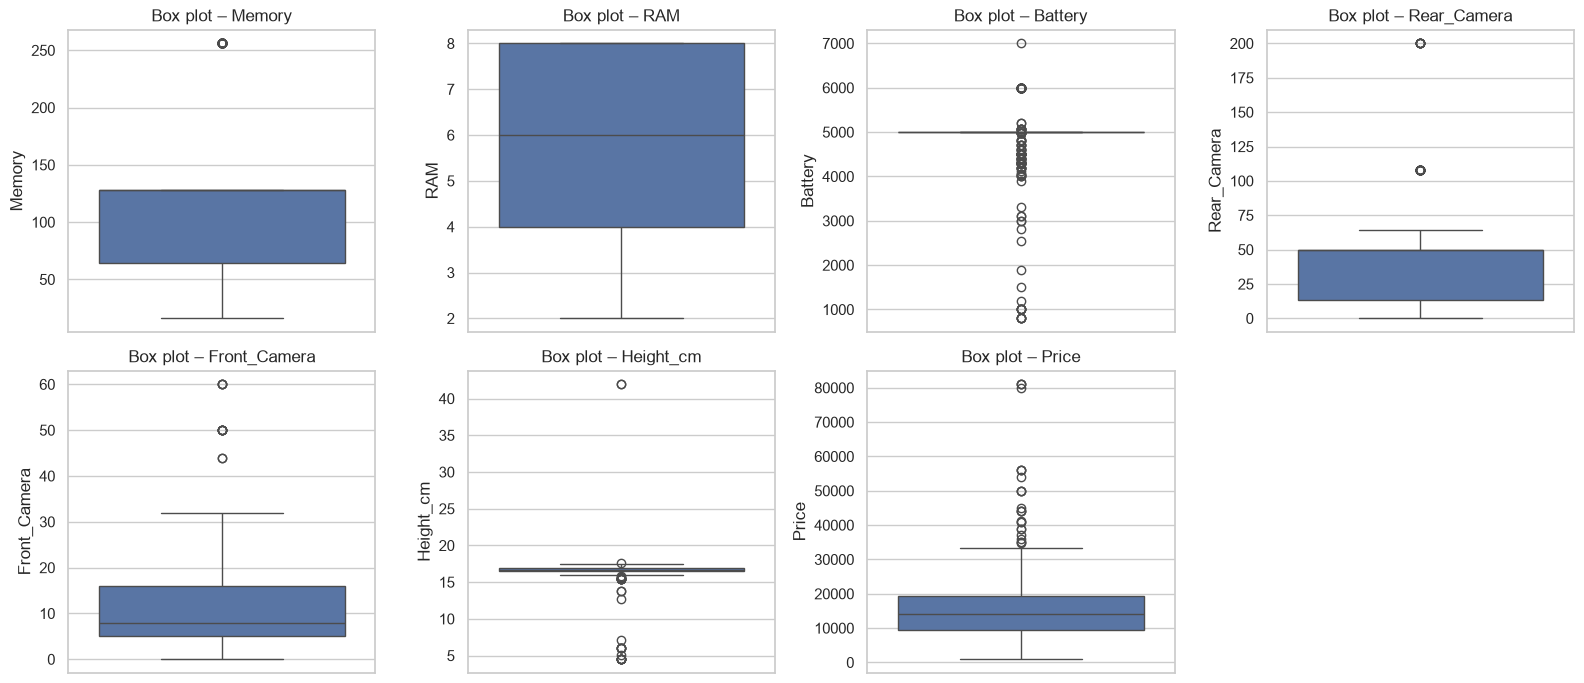

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#4C72B0")
    ax.set_title(f"Box plot – {c}")
axes.ravel()[-1].axis("off")
save_show("01_outlier_boxplots")

**Interpretation (box plots for every numeric column, as the instructor asked)**
- **Price:** 25 IQR outliers, up to ₹80,999 – the genuine premium phones (iPhone 14 Plus, Galaxy S23, Pixel 7), not errors.
- **Battery:** 148 "outliers" only because 72 % of phones have exactly 5000 mAh, so the IQR is almost zero and every other value is flagged. A quirk of the method, not bad data.
- **Memory (55) and Rear_Camera (39):** the high values (256 GB, 108–200 MP) are real specifications of mid-range and premium phones; Front_Camera has 13 and **RAM has none**.
- **Height:** the real problem – two points at 41.94 cm (impossible) plus a cluster at 4.5–7 cm (basic phones). Only the 41.94 cm values are errors.

In [21]:
print(df.loc[df["Height_cm"] > 20, ["Model", "Height_cm", "Price"]])
print("\nBasic / feature phones (height below 10 cm):", (df["Height_cm"] < 10).sum())

              Model  Height_cm  Price
73  MOTOROLA G62 5G      41.94  16499
86  MOTOROLA G62 5G      41.94  16499

Basic / feature phones (height below 10 cm): 15


**Decision on outliers (not blind removal):**
- **Height 41.94 cm** (2 rows of *Motorola G62 5G*) is physically impossible for a phone → **data-entry error**. We set it to *missing*; the missing value is imputed later with the **training-set median inside the modelling pipeline**, so no test-set information is used.
- **Very low prices / small batteries / small heights** belong to genuine basic phones (Micromax, etc.) → these are real market segments, **kept**. We will create a feature that flags them.
- **Very high prices** (iPhone 14 Plus, Galaxy S23, Pixel 7) are real premium phones → **kept**. Removing them would stop the model from ever learning what a premium phone looks like.

In [22]:
# brand is needed to impute height, so extract it now (full explanation in Step 3)
BRANDS = {"apple": "Apple", "google": "Google", "i kall": "IKall", "iqoo": "iQOO", "infinix": "Infinix",
          "lava": "Lava", "motorola": "Motorola", "micromax": "Micromax", "nokia": "Nokia", "oppo": "OPPO",
          "oneplus": "OnePlus", "poco": "POCO", "redmi": "Redmi", "samsung": "Samsung", "tecno": "Tecno",
          "itel": "itel", "nothing": "Nothing", "realme": "realme", "vivo": "vivo"}
def get_brand(model):
    m = model.lower()
    for key, val in BRANDS.items():
        if m.startswith(key):
            return val
    return "Other"
df["Brand"] = df["Model"].map(get_brand)

bad = df["Height_cm"] > 20
df.loc[bad, "Height_cm"] = np.nan
print("Impossible heights set to missing:", int(bad.sum()))
print("New max height:", df["Height_cm"].max())

Impossible heights set to missing: 2
New max height: 17.65


## Step 3 – EDA together with Feature Engineering
Following the process taught in the sessions: while exploring the data (univariate → bivariate → multivariate) we **create, extract, drop and transform** features.

### 3.1 Univariate analysis – the target variable first

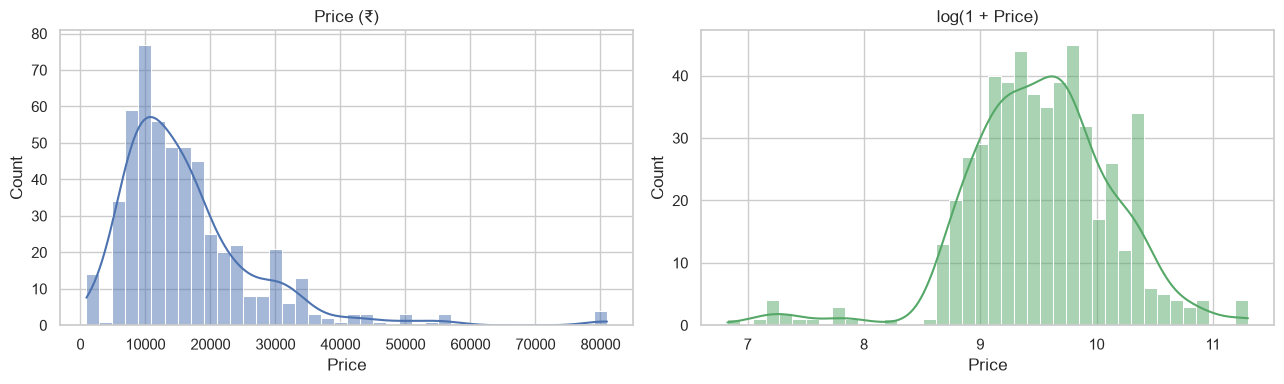

Skewness of Price: 2.42 | skewness of log price: -0.6
count      531.0
mean     16306.0
std      10847.0
min        920.0
25%       9368.0
50%      13999.0
75%      19338.0
max      80999.0
Name: Price, dtype: float64


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Price"], bins=40, kde=True, ax=ax[0], color="#4C72B0"); ax[0].set_title("Price (₹)")
sns.histplot(np.log1p(df["Price"]), bins=40, kde=True, ax=ax[1], color="#55A868"); ax[1].set_title("log(1 + Price)")
save_show("02_price_distribution")
print("Skewness of Price:", round(df["Price"].skew(), 2), "| skewness of log price:", round(np.log1p(df["Price"]).skew(), 2))
print(df["Price"].describe().round(0))

**Interpretation**
- Price is strongly **right-skewed (skewness 2.42)**: the median is ₹13,999 but the mean is higher (₹16,306) because a small number of premium phones pull the average up. Half of the phones cost between roughly ₹9,400 and ₹19,300.
- After the log transform the shape is much more symmetric (skewness −0.60). This tells us that prices behave *multiplicatively* (a better phone costs x % more, not a fixed amount more), so we will test a log-price target when modelling.
- For reporting we rely on the **median** and on MAE/RMSE rather than on the mean alone.

### 3.2 Univariate – hardware specifications

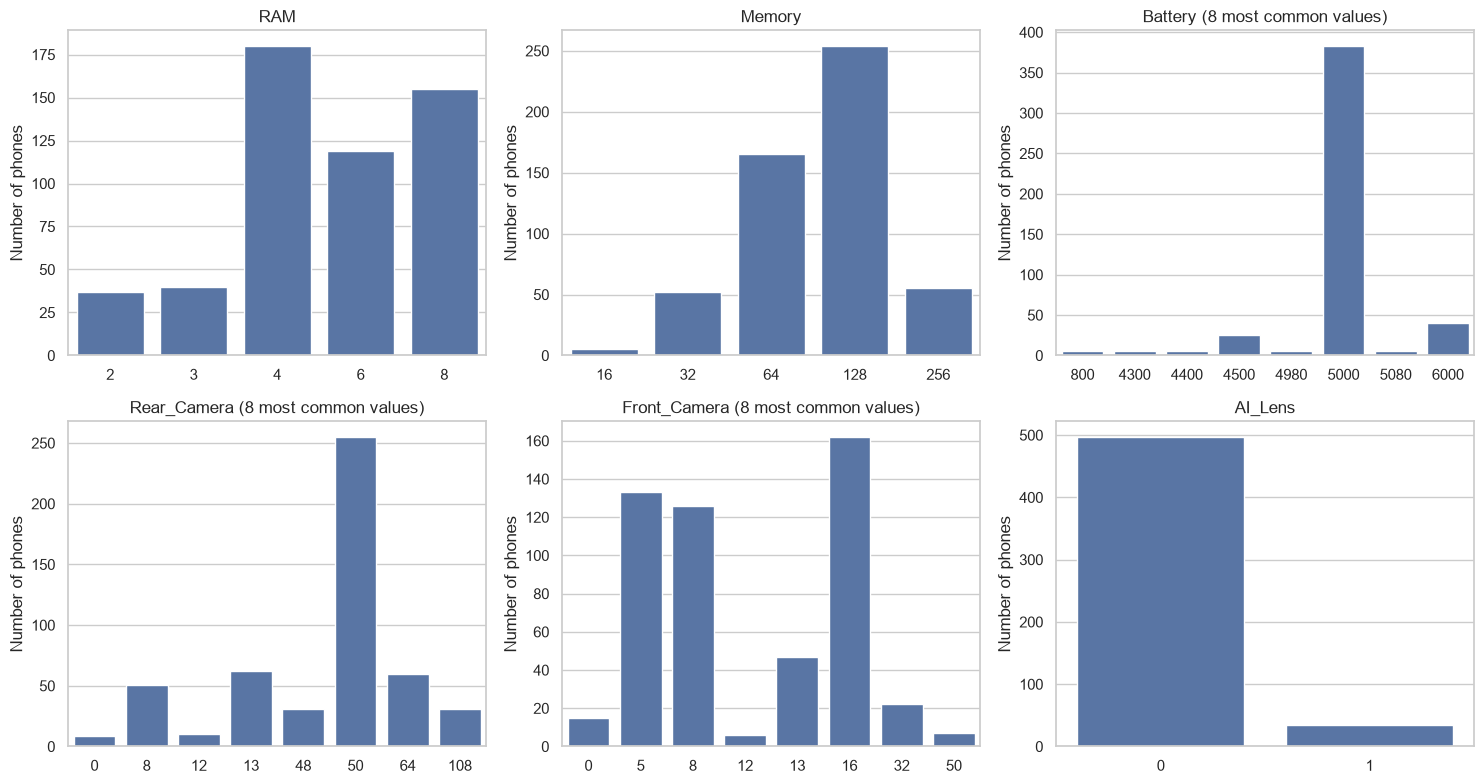

RAM shares: {2: 0.07, 3: 0.08, 4: 0.34, 6: 0.22, 8: 0.29}
Storage shares: {16: 0.01, 32: 0.1, 64: 0.31, 128: 0.48, 256: 0.1}
0.72 of phones have a 5000 mAh battery; 0.48 have a 50 MP rear camera; 0.064 have an AI lens


In [24]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(ax.ravel(), ["RAM", "Memory", "Battery", "Rear_Camera", "Front_Camera", "AI_Lens"]):
    if c in ["Battery", "Rear_Camera", "Front_Camera"]:
        top = df[c].value_counts().head(8).sort_index()
        sns.barplot(x=top.index.astype(str), y=top.values, ax=a, color="#4C72B0")
        a.set_title(f"{c} (8 most common values)")
    else:
        sns.countplot(x=df[c], ax=a, color="#4C72B0"); a.set_title(c)
    a.set_ylabel("Number of phones"); a.set_xlabel("")
save_show("03_spec_distributions")
print("RAM shares:", df["RAM"].value_counts(normalize=True).round(2).sort_index().to_dict())
print("Storage shares:", df["Memory"].value_counts(normalize=True).round(2).sort_index().to_dict())
print((df["Battery"] == 5000).mean().round(2), "of phones have a 5000 mAh battery;",
      (df["Rear_Camera"] == 50).mean().round(2), "have a 50 MP rear camera;",
      df["AI_Lens"].mean().round(3), "have an AI lens")

**Interpretation**
- The catalogue is dominated by **budget and mid-range** phones: 4 GB (34 %), 8 GB (29 %) and 6 GB (22 %) of RAM; 128 GB storage in 48 % of phones.
- **Battery has almost no variety** – 72 % of phones are at 5000 mAh – so it cannot separate cheap from expensive phones by itself.
- 48 % of phones advertise a 50 MP rear camera and only 6.4 % have an AI lens, so the AI-lens feature rests on few examples (34 phones).

### 3.3 Feature engineering #1 – **Feature extraction from `Model`: the `Brand`**
`Model` has 187 different values, which is far too many to use directly (and each model is almost a unique ID). But the **brand is hidden inside the model name**, so we extract it (already created in step 2.5).

In [25]:
brand_summary = df.groupby("Brand")["Price"].agg(["count", "median"]).sort_values("count", ascending=False)
brand_summary

,count,median
Brand,,
realme,97,12499.0
Redmi,74,14999.0
Infinix,65,8999.0
vivo,60,17999.0
POCO,58,14499.0
Samsung,53,16999.0
Motorola,45,13999.0
Tecno,16,8368.5
OPPO,16,14249.0


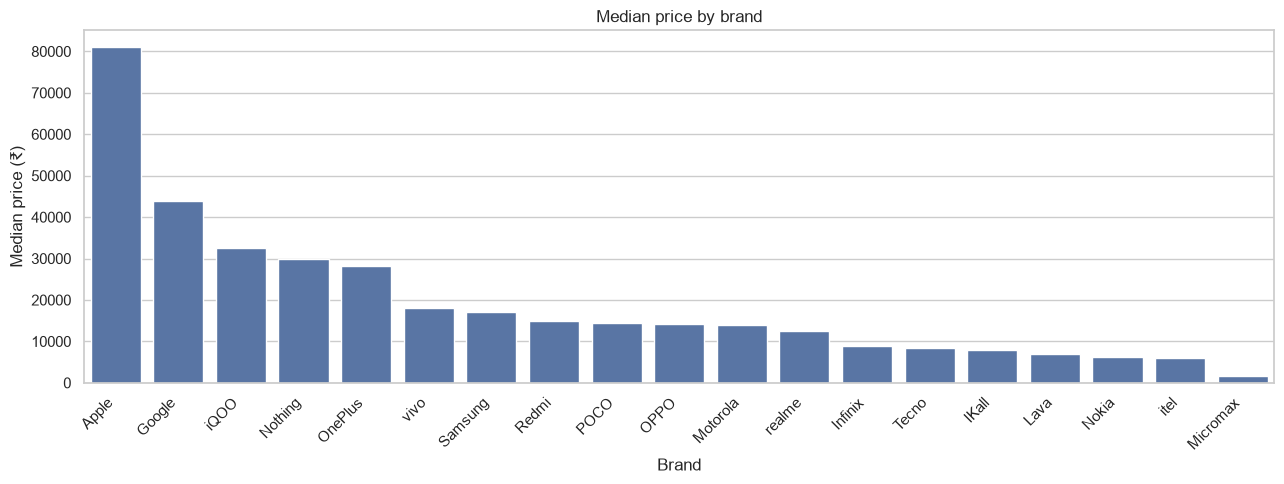

In [26]:
order = df.groupby("Brand")["Price"].median().sort_values(ascending=False).index
plt.figure(figsize=(13, 5))
sns.barplot(data=df, x="Brand", y="Price", order=order, estimator=np.median, errorbar=None, color="#4C72B0")
plt.xticks(rotation=45, ha="right"); plt.ylabel("Median price (₹)"); plt.title("Median price by brand")
save_show("04_brand_price")

**Interpretation**
- Brands form clear **price positions**: premium – Apple (₹80,999), Google (₹43,999), iQOO, Nothing, OnePlus (₹28–33 k); mainstream – realme, Motorola, POCO, Redmi, Samsung, vivo (₹12.5–18 k); budget – Micromax (₹1,724), itel, Nokia, Lava, Tecno, Infinix (below ₹9 k).
- Caution: the premium brands have only 2–9 phones each, so their medians are less reliable than the medians of realme (97 phones) or Redmi (74).
- Brand is therefore informative, but it will overlap with what the processor already tells us (next plot).

### 3.4 Feature engineering #2 – **Feature extraction from `Processor`**
The `Processor` column has 123 spellings for roughly 60 real chips (e.g. *"Qualcomm Snapdragon 680"*, *"Snapdragon 680"*, *"Qualcomm SM6225 Snapdragon 680 4G (6 nm)"*). Instead of one-hot encoding 123 values we extract two meaningful features:
1. **`Chipmaker`** – Qualcomm, MediaTek, Unisoc, Samsung, Apple, Google (a handful of categories).
2. **`Processor_Tier`** – an *ordered* performance class built **only from the chip name** (never from the price, to avoid target leakage):
   `0` = basic (Unisoc, Helio A/G25–G37/P35 …), `1` = mid-range (Helio G8x–G99, Snapdragon 680/695, Dimensity 700 …), `2` = upper-mid (Snapdragon 7xx, Dimensity 810–1300 …), `3` = flagship (Snapdragon 8-series/888, Dimensity 8000/9000, Apple, Tensor).

In [27]:
def get_chipmaker(row):
    s = row["Processor"].lower()
    if row["Brand"] == "Apple" or s == "ios": return "Apple"
    if any(k in s for k in ["snapdragon", "qualcomm"]): return "Qualcomm"
    if any(k in s for k in ["mediatek", "mtk", "helio", "dimensity", "meditek", "mt62"]) or s == "g37": return "MediaTek"
    if any(k in s for k in ["unisoc", "spreadtrum", "sc9863", "sc6531"]): return "Unisoc"
    if any(k in s for k in ["exynos", "sec s5e"]): return "Samsung"
    if "tensor" in s: return "Google"
    return "Unknown"

def get_tier(row):
    s = row["Processor"].lower()
    if row["Chipmaker"] in ("Apple", "Google"): return 3
    if re.search(r"8 gen|8\+ gen|888|865|855|845|dimensity (8|9)\d{3}|exynos 2", s): return 3
    if re.search(r"778|7\+ gen|750|730|720|765|dimensity (1080|1300|7200|900|920|930|810|800)|exynos 1[34]80", s): return 2
    if re.search(r"helio (g7|g8|g9|p)|g85|g88|g95|g96|g99|snapdragon 68|snapdragon 695|4 gen 1|dimensity (700|6020)|exynos 850|exynos 1330|s5e8535", s): return 1
    if re.search(r"helio a|g25|g35|g36|g37|p35|439|unisoc|spreadtrum|sc9863|sc6531|mt62|mtk62", s): return 0
    return np.nan

df["Chipmaker"] = df.apply(get_chipmaker, axis=1)
df["Processor_Tier"] = df.apply(get_tier, axis=1)
print("Processor names that could not be classified (e.g. 'Octa Core'):", df["Processor_Tier"].isna().sum())
print(df.loc[df["Processor_Tier"].isna(), "Processor"].value_counts())

Processor names that could not be classified (e.g. 'Octa Core'): 19
Processor
Octa Core            5
MediaTek             3
Octa-core(EXYNOS)    3
2GHz, Quad Core      2
Oxygen OS            2
0 0 0 208MHz         1
Android              1
Octa-core            1
Exynos Octa Core     1
Name: count, dtype: int64


In [28]:
# Vague chip text such as "Octa Core" does not identify the chip -> we do NOT guess; the tier stays missing
# (it is imputed with the training median, plus a missing-indicator, inside the modelling pipeline)
print(df["Processor_Tier"].value_counts(dropna=False).sort_index())
print(df["Chipmaker"].value_counts())

Processor_Tier
0.0    144
1.0    214
2.0    114
3.0     40
NaN     19
Name: count, dtype: int64
Chipmaker
MediaTek    280
Qualcomm    129
Unisoc       69
Samsung      28
Unknown      12
Google        8
Apple         5
Name: count, dtype: int64


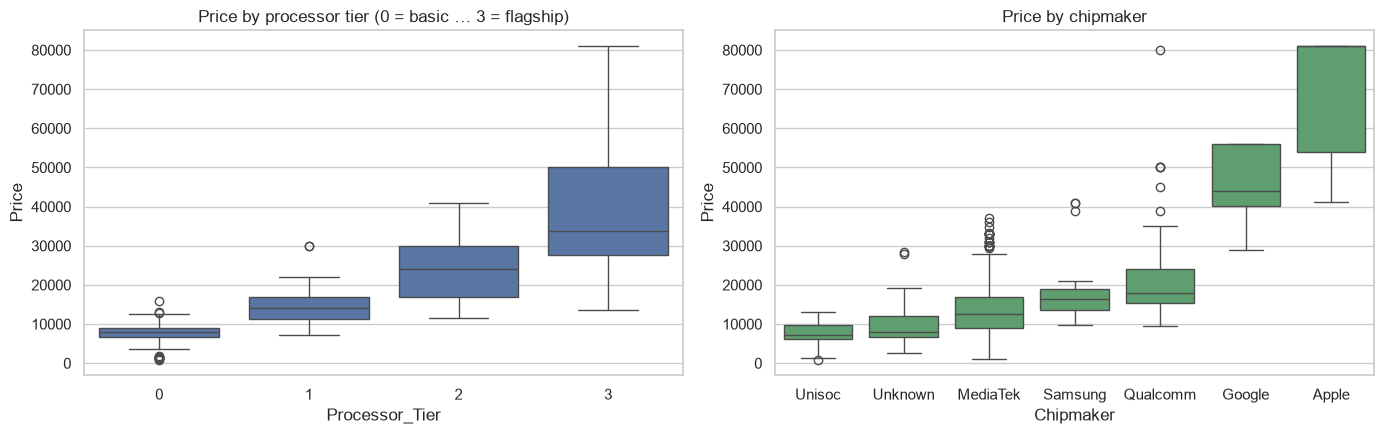

Processor_Tier
0.0     7999.0
1.0    13999.0
2.0    23999.0
3.0    33843.5
Name: Price, dtype: float64
           count   median
Chipmaker                
Unisoc        69   7299.0
Unknown       12   7999.0
MediaTek     280  12549.0
Samsung       28  16499.0
Qualcomm     129  17999.0
Google         8  43999.0
Apple          5  80999.0


In [29]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df.dropna(subset=["Processor_Tier"]).astype({"Processor_Tier": int}), x="Processor_Tier", y="Price", ax=ax[0], color="#4C72B0")
ax[0].set_title("Price by processor tier (0 = basic … 3 = flagship)")
order = df.groupby("Chipmaker")["Price"].median().sort_values().index
sns.boxplot(data=df, x="Chipmaker", y="Price", order=order, ax=ax[1], color="#55A868")
ax[1].set_title("Price by chipmaker")
save_show("05_processor")
print(df.groupby("Processor_Tier")["Price"].median())
print(df.groupby("Chipmaker")["Price"].agg(["count", "median"]).sort_values("median"))

**Interpretation**
- **Processor tier shows a clean staircase:** median price rises from ₹7,999 (tier 0) to ₹13,999 (tier 1), ₹23,999 (tier 2) and ₹33,844 (tier 3). The boxes of tier 0 and tier 2/3 barely overlap. (The 19 phones whose chip text is too vague to classify are left out of this plot.)
- **Chipmaker alone is a blunter signal:** Unisoc (₹7,299) < MediaTek (₹12,549) < Samsung (₹16,499) < Qualcomm (₹17,999) < Google (₹43,999) < Apple (₹80,999). One maker sells both entry-level and high-end chips, which is why the tier we engineered is more informative than the raw maker.

### 3.5 Feature engineering #3 – **Colour family** (as suggested in feedback)
There are 275 different colour names (*Glacier Blue, Aqua Blue, Lake Blue …*). We group them into a few **colour families**.

In [30]:
COLOUR_RULES = [
    ("Black", ["black", "charcoal", "obsidian", "onyx", "midnight", "graphite", "dark matter", "hyperspace", "night", "carbon", "nitro", "phantom"]),
    ("Blue", ["blue", "cyan", "aqua", "azure", "navy", "sea", "ocean", "glacier", "arctic", "ice", "lake", "sky", "marine", "denim", "uyuni", "turquoise"]),
    ("Green", ["green", "mint", "olive", "jade", "emerald", "forest", "rainforest", "lime", "vert", "lemongrass"]),
    ("White", ["white", "snow", "chalk", "cream", "pearl", "starlight", "frost", "lily"]),
    ("Gray/Silver", ["gr", "silver", "steel", "slate", "meteor", "shadow", "mithril", "volcanic"]),
    ("Gold/Orange/Yellow", ["gold", "orange", "copper", "peach", "marigold", "sunshine", "sunrise", "sunset", "yellow", "sandy"]),
    ("Purple/Pink/Red", ["purple", "violet", "red", "rose", "pink", "lavender", "iris", "fantasy", "peppy"]),
]
def colour_family(c):
    c = c.lower()
    for family, keys in COLOUR_RULES:
        if any(k in c for k in keys):
            return family
    return "Other"
df["Colour_Family"] = df["Colour"].map(colour_family)
print(df["Colour_Family"].value_counts())

Colour_Family
Black                 172
Blue                  148
Green                  60
Gold/Orange/Yellow     50
Gray/Silver            34
White                  30
Purple/Pink/Red        24
Other                  13
Name: count, dtype: int64


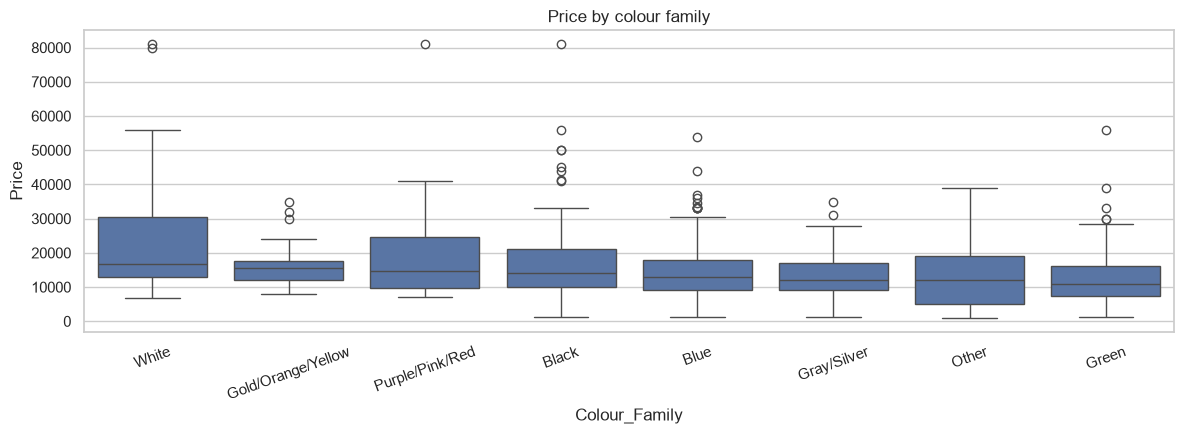

                    count   median
Colour_Family                     
White                  30  16749.0
Gold/Orange/Yellow     50  15499.0
Purple/Pink/Red        24  14744.5
Black                 172  13999.0
Blue                  148  12945.0
Gray/Silver            34  11999.0
Other                  13  11999.0
Green                  60  10999.0

Most common brand inside each colour family:
Colour_Family
Black                   realme
Blue                    realme
Gold/Orange/Yellow        POCO
Gray/Silver           Motorola
Green                    Redmi
Other                    Redmi
Purple/Pink/Red        Samsung
White                  Infinix
dtype: str


In [31]:
order = df.groupby("Colour_Family")["Price"].median().sort_values(ascending=False).index
plt.figure(figsize=(12, 4.5))
sns.boxplot(data=df, x="Colour_Family", y="Price", order=order, color="#4C72B0")
plt.xticks(rotation=20); plt.title("Price by colour family")
save_show("06_colour_price")
print(df.groupby("Colour_Family")["Price"].agg(["count", "median"]).sort_values("median", ascending=False))
print("\nMost common brand inside each colour family:")
print(pd.crosstab(df["Colour_Family"], df["Brand"], normalize="index").idxmax(axis=1))

**Interpretation**
- The boxes of all colour families **overlap heavily**; medians run only from ₹10,999 (green) to ₹16,749 (white), a much smaller spread than the spread *inside* each family.
- The differences mostly reflect *which phones come in which colour* – e.g. the ₹80,999 iPhones appear under white, purple/pink and black, which lifts those medians. Colour is not what customers pay for.
- Later, mutual information confirms this (≈ 0 for every colour column), so colour is dropped from the model.

### 3.6 Feature engineering #4 – other useful features
| New feature | Idea | How it is built |
|---|---|---|
| `Is_5G` | 5G phones are newer and costlier | "5G" in the model/chip name, or a MediaTek Dimensity chip |
| `Is_Feature_Phone` | Basic phones are a separate segment | `Height_cm < 10` (smartphones are ~15–17 cm) |
| `Storage_RAM_Ratio` | Balance between storage and RAM | `Memory / RAM` |

In [32]:
df["Is_5G"] = (df["Model"].str.lower().str.contains("5g") |
               df["Processor"].str.lower().str.contains("5g|dimensity")).astype(int)
df["Is_Feature_Phone"] = (df["Height_cm"] < 10).astype(int)
df["Storage_RAM_Ratio"] = (df["Memory"] / df["RAM"]).round(2)
print(df[["Is_5G", "Is_Feature_Phone"]].mean().round(3))
df.groupby("Is_5G")["Price"].agg(["count", "median", "mean"]).round(0)

Is_5G               0.365
Is_Feature_Phone    0.028
dtype: float64


,count,median,mean
Is_5G,,,
0,337,9999.0,12905.0
1,194,19999.0,22213.0


### 3.7 Bivariate analysis – how do the specifications relate to price?

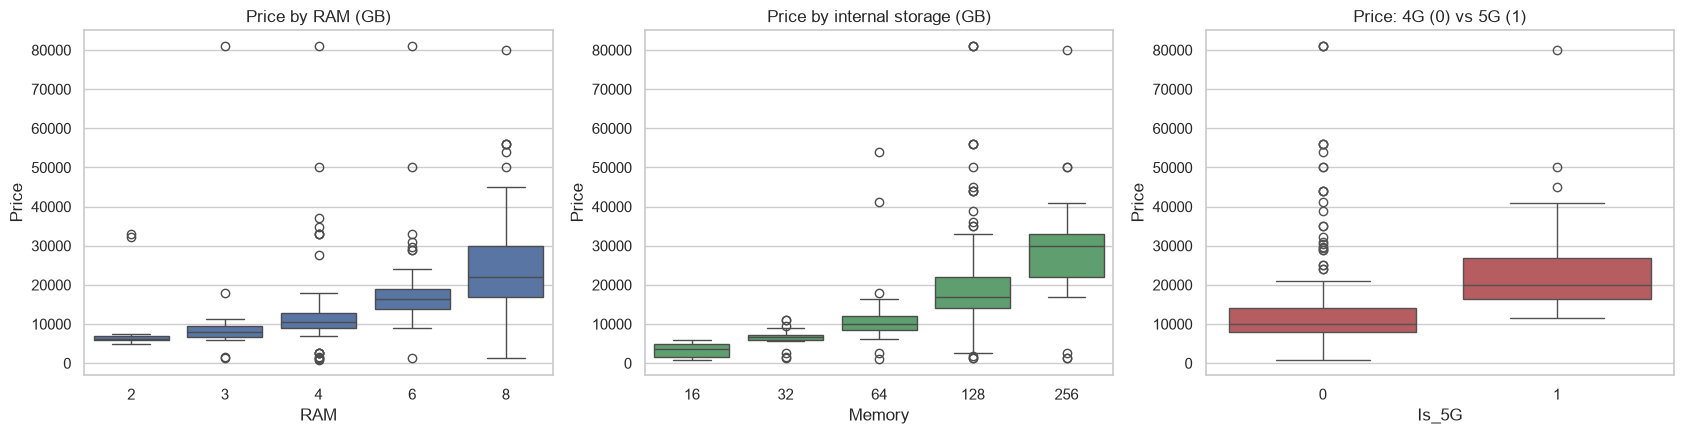

RAM
2     6299.0
3     7994.5
4    10499.0
6    16499.0
8    21999.0
Name: Price, dtype: float64
Memory
16      3549.0
32      6599.0
64      9999.0
128    16999.0
256    29999.0
Name: Price, dtype: float64


In [33]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=df, x="RAM", y="Price", ax=ax[0], color="#4C72B0"); ax[0].set_title("Price by RAM (GB)")
sns.boxplot(data=df, x="Memory", y="Price", ax=ax[1], color="#55A868"); ax[1].set_title("Price by internal storage (GB)")
sns.boxplot(data=df, x="Is_5G", y="Price", ax=ax[2], color="#C44E52"); ax[2].set_title("Price: 4G (0) vs 5G (1)")
save_show("07_ram_memory_5g")
print(df.groupby("RAM")["Price"].median())
print(df.groupby("Memory")["Price"].median())

**Interpretation**
- **RAM:** median price climbs with each step – 2 GB ₹6,299 → 4 GB ₹10,499 → 6 GB ₹16,499 → 8 GB ₹21,999.
- **Storage rises even faster:** 16 GB ₹3,549 → 64 GB ₹9,999 → 128 GB ₹16,999 → 256 GB ₹29,999.
- **5G phones cost about twice as much** (median ₹19,999 vs ₹9,999 for 4G), partly because 5G comes together with better chips.
- Within every RAM or storage class the boxes are wide, so RAM or storage alone cannot fix the price – other features (chip, brand) matter as well.

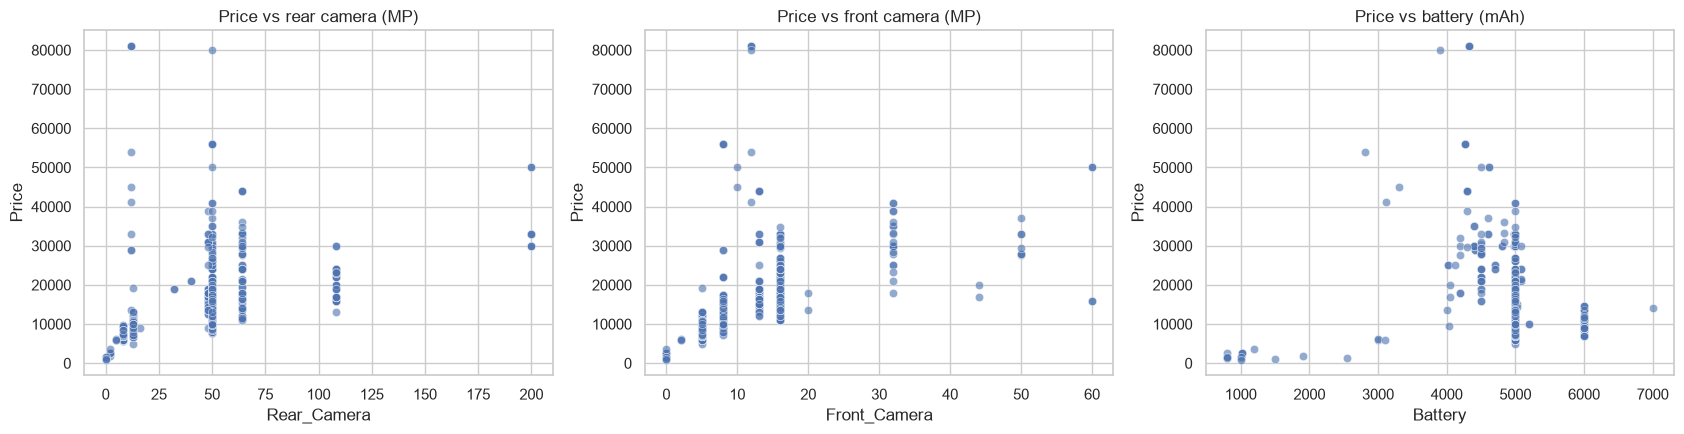

Rear_Camera     0.62
Front_Camera    0.81
Battery        -0.31
Price           1.00
Name: Price, dtype: float64


In [34]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(data=df, x="Rear_Camera", y="Price", ax=ax[0], alpha=0.6); ax[0].set_title("Price vs rear camera (MP)")
sns.scatterplot(data=df, x="Front_Camera", y="Price", ax=ax[1], alpha=0.6); ax[1].set_title("Price vs front camera (MP)")
sns.scatterplot(data=df, x="Battery", y="Price", ax=ax[2], alpha=0.6); ax[2].set_title("Price vs battery (mAh)")
save_show("08_camera_battery")
print(df[["Rear_Camera", "Front_Camera", "Battery", "Price"]].corr(method="spearman")["Price"].round(2))

**Interpretation**
- **Front camera has the strongest relation with price (Spearman 0.81)**, rear camera is lower (0.62). The front-camera resolution jumps with the market segment (5 MP in budget phones, 16–32 MP in mid-range), so it acts as a *proxy for the segment* rather than being the cause of the price.
- Rear camera megapixels are a weaker signal: the 50 MP cluster stretches from cheap to expensive phones, i.e. the same megapixel figure is sold at very different prices.
- **Battery is negatively related to price (−0.31):** budget phones carry 5000–6000 mAh, while the iPhone, Pixel and Galaxy S phones are at ~3,900–4,300 mAh. A bigger battery does not make a phone more expensive.

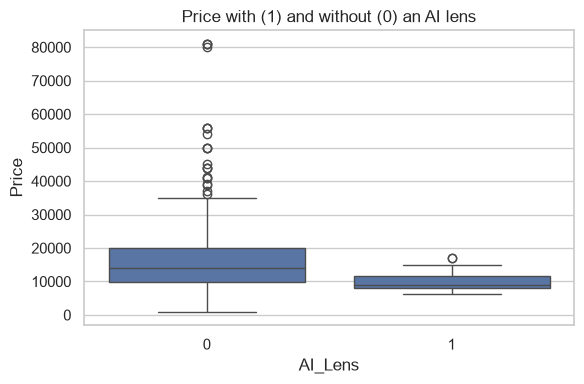

         count   median
AI_Lens                
0          497  13999.0
1           34   8999.0


In [35]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="AI_Lens", y="Price", color="#4C72B0")
plt.title("Price with (1) and without (0) an AI lens")
save_show("09_ai_lens")
print(df.groupby("AI_Lens")["Price"].agg(["count", "median"]))

**Interpretation**
- Phones **with** an AI lens are actually cheaper (median ₹8,999, 34 phones) than phones without one (₹13,999). The AI lens is mainly advertised on budget phones, so it does not add a price premium. The sample is small, so we treat this as weak evidence.

### 3.8 Multivariate analysis

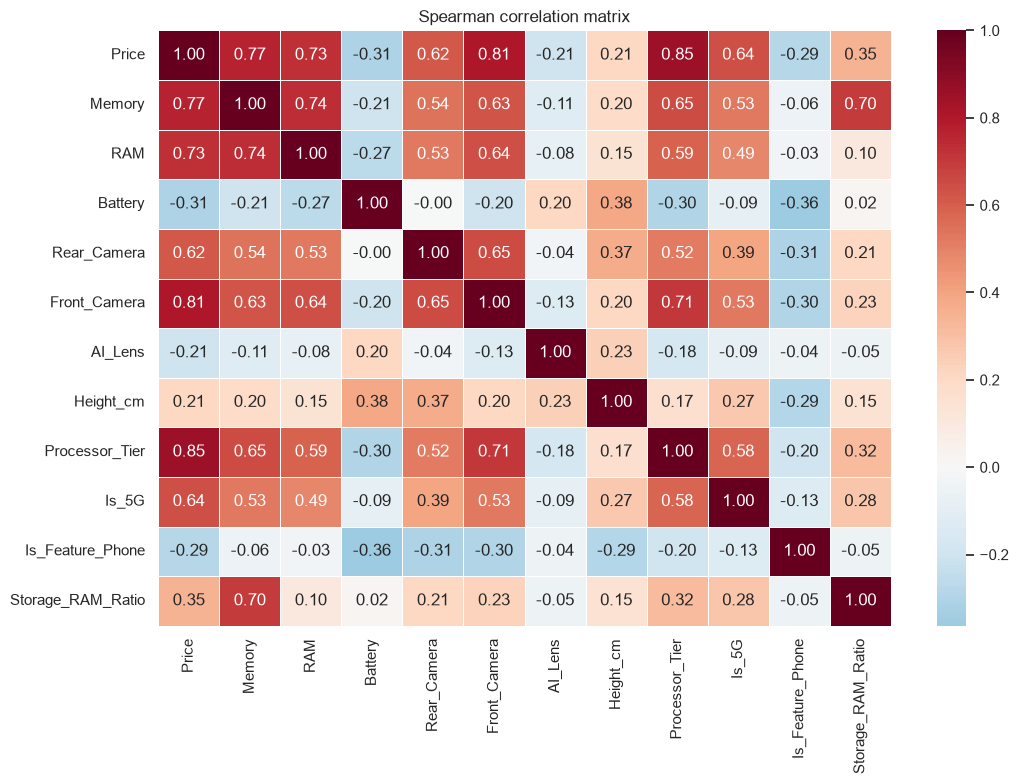

Processor_Tier       0.85
Front_Camera         0.81
Memory               0.77
RAM                  0.73
Is_5G                0.64
Rear_Camera          0.62
Storage_RAM_Ratio    0.35
Height_cm            0.21
AI_Lens             -0.21
Is_Feature_Phone    -0.29
Battery             -0.31
Name: Price, dtype: float64


In [36]:
corr_cols = ["Price", "Memory", "RAM", "Battery", "Rear_Camera", "Front_Camera", "AI_Lens",
             "Height_cm", "Processor_Tier", "Is_5G", "Is_Feature_Phone", "Storage_RAM_Ratio"]
plt.figure(figsize=(11, 8))
sns.heatmap(df[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5)
plt.title("Spearman correlation matrix")
save_show("10_correlation")
print(df[corr_cols].corr(method="spearman")["Price"].drop("Price").sort_values(ascending=False).round(2))

**Interpretation**
- Features most related to price: **Processor_Tier (0.85), Front_Camera (0.81), Memory (0.77), RAM (0.73), Is_5G (0.64), Rear_Camera (0.62)**.
- Weak or negative: Battery (−0.31), Is_Feature_Phone (−0.29), AI_Lens (−0.21), Height (0.21).
- The strong features are also **correlated with each other** (e.g. Memory–RAM 0.74, Front camera–Processor tier 0.71): they all describe the same thing – how high-end the phone is. This is why correlation alone cannot tell us which feature *drives* the price, and why we add model-based importance later.

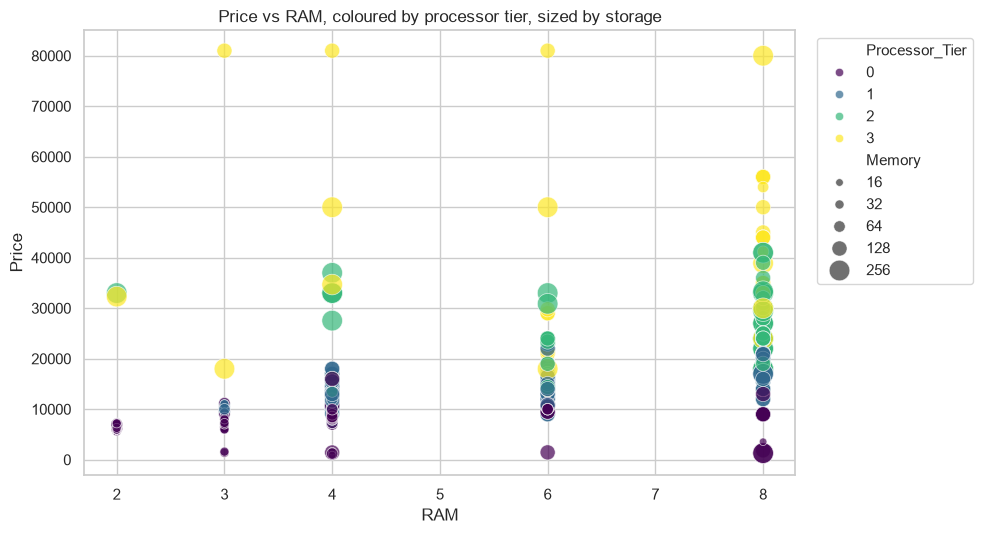

In [37]:
plt.figure(figsize=(10, 5.5))
sns.scatterplot(data=df.dropna(subset=["Processor_Tier"]).astype({"Processor_Tier": int}), x="RAM", y="Price", hue="Processor_Tier", palette="viridis", size="Memory", sizes=(30, 220), alpha=0.7)
plt.title("Price vs RAM, coloured by processor tier, sized by storage")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
save_show("11_multivariate")

**Interpretation**
- Moving to the right (more RAM) and up (higher price), the colour changes from dark purple (tier 0) to yellow (tier 3). **Inside the same RAM level, the higher-tier chip phones are clearly more expensive**, so processor tier adds information beyond RAM.
- Bigger circles (more storage) sit higher on the price axis for the same RAM, showing that storage adds its own premium.
- The best explanation of price is therefore a *combination* of chip class, RAM and storage.
- Data-quality warning visible here: the ₹80,999 iPhone 14 Plus is listed with 3, 4 and 6 GB RAM, and a few ~₹1,300 basic phones are listed with 8 GB RAM. These are inconsistent entries in the source file, which is another reason why RAM alone is an unreliable price signal and why the chip tier is so valuable.

### 3.8b Comparing price segments (EDA only)
A price-segment column is created **for exploration only** – it is built from the target, so it is *never* used as a model input (that would leak the answer).

                     Phones  Median_price  Median_RAM  Median_storage_GB  Median_front_MP  Share_5G  Median_processor_tier
Price_Band                                                                                                                
Budget (< ₹10k)         174        7999.0         4.0               64.0              5.0      0.00                    0.0
Mid-range (₹10–30k)     311       16499.0         6.0              128.0             16.0      0.54                    1.0
Premium (> ₹30k)         46       34999.0         8.0              128.0             16.0      0.59                    2.5


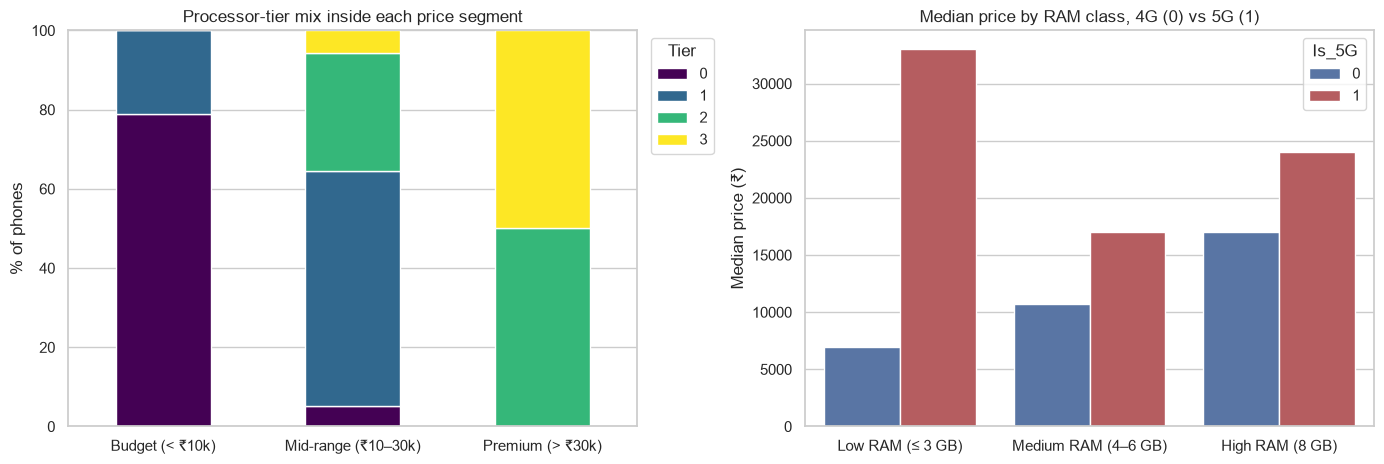

In [38]:
df["Price_Band"] = pd.cut(df["Price"], [0, 10000, 30000, np.inf], labels=["Budget (< ₹10k)", "Mid-range (₹10–30k)", "Premium (> ₹30k)"])
df["RAM_Class"] = pd.cut(df["RAM"], [0, 3, 6, 8], labels=["Low RAM (≤ 3 GB)", "Medium RAM (4–6 GB)", "High RAM (8 GB)"])

band = df.groupby("Price_Band", observed=True).agg(Phones=("Price", "size"), Median_price=("Price", "median"), Median_RAM=("RAM", "median"),
        Median_storage_GB=("Memory", "median"), Median_front_MP=("Front_Camera", "median"), Share_5G=("Is_5G", "mean"),
        Median_processor_tier=("Processor_Tier", "median")).round(2)
print(band.to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
tier_mix = pd.crosstab(df["Price_Band"], df["Processor_Tier"].astype("Int64"), normalize="index") * 100
tier_mix.plot(kind="bar", stacked=True, ax=ax[0], colormap="viridis"); ax[0].set_ylabel("% of phones"); ax[0].set_xlabel("")
ax[0].set_title("Processor-tier mix inside each price segment"); ax[0].tick_params(axis="x", rotation=0); ax[0].legend(title="Tier", bbox_to_anchor=(1.01, 1))
sns.barplot(data=df, x="RAM_Class", y="Price", hue="Is_5G", estimator=np.median, errorbar=None, ax=ax[1], palette=["#4C72B0", "#C44E52"])
ax[1].set_title("Median price by RAM class, 4G (0) vs 5G (1)"); ax[1].set_xlabel(""); ax[1].set_ylabel("Median price (₹)")
save_show("11b_price_segments")

**Interpretation (EDA only – the price segments are not model inputs)**
- The data set has 174 budget phones (median ₹7,999), 311 mid-range phones (₹16,499) and only **46 premium phones** (₹34,999) – the premium segment is thin.
- **Processor tier separates the segments (left chart):** about 79 % of budget phones have a basic (tier 0) chip and none have a high-end one; the mid-range is mostly tier 1–2; every premium phone has a tier 2 or tier 3 chip (about half tier 3).
- Median front camera rises 5 MP → 16 MP → 16 MP and 5G is absent in the budget segment (0 %) but present in 54 % of mid-range and 59 % of premium phones.
- **Right chart:** within the same RAM class, 5G phones have a clearly higher median price than 4G phones. The very high bar for "low RAM + 5G" is not a real effect – it comes from iPhones that are listed with only 3–4 GB RAM in the source data (a data-quality issue noted earlier).

### 3.9 Feature transformation – encoding (done inside the modelling pipeline)
Machines only understand numbers, so categories must be encoded. Two corrections were made compared with a first version of this notebook:

- **`Brand` is a nominal category, not a scale.** Label-encoding it (Apple = 0 … vivo = 18) would tell the models that vivo is "greater than" Apple. We therefore use **one-hot encoding for Brand, Chipmaker and Colour_Family** (`OneHotEncoder(handle_unknown="ignore")`).
- **Every fitted step (imputation, scaling, encoding, feature selection) lives in a scikit-learn `Pipeline` and is fitted on the training data only** – never on the full data set – and is re-fitted inside every cross-validation fold.
- `Processor_Tier` is already numeric with a natural order (0 < 1 < 2 < 3), so it is kept as it is.

### 3.10 Validate the engineered features and build a data-quality report
Hand-made features must be checked, not trusted. First the three rule-based features:

In [39]:
# --- Processor tier: which processor strings could NOT be classified? (kept as unknown, not guessed)
unk = df[df["Processor_Tier"].isna()]
print(f"{len(unk)} rows have an unclassifiable processor text -> Processor_Tier stays missing (imputed later, with a missing-indicator)")
print(unk["Processor"].value_counts().to_string())

# --- Is_5G: where does the flag rely on the processor text only (model name has no '5G')?
model_5g = df["Model"].str.lower().str.contains("5g")
only_chip = df[(df["Is_5G"] == 1) & (~model_5g)]
print(f"\nIs_5G = 1 for {df['Is_5G'].sum()} phones; {len(only_chip)} of them rely only on the processor text (e.g. Dimensity chips).")
print(only_chip[["Model", "Processor"]].head(8).to_string(index=False))

# --- Is_Feature_Phone: does the height rule match the model names and specs?
fp = df[df["Is_Feature_Phone"] == 1]
print(f"\nFlagged as feature phone: {len(fp)} rows, brands: {fp['Brand'].value_counts().to_dict()}")
print("Largest rear camera among flagged phones:", fp["Rear_Camera"].max(), "MP | median price:", fp["Price"].median())
print("Smartphones (height >= 10 cm) with battery < 2500 mAh that are NOT flagged:",
      ((df["Height_cm"] >= 10) & (df["Battery"] < 2500)).sum())

19 rows have an unclassifiable processor text -> Processor_Tier stays missing (imputed later, with a missing-indicator)
Processor
Octa Core            5
MediaTek             3
Octa-core(EXYNOS)    3
2GHz, Quad Core      2
Oxygen OS            2
0 0 0 208MHz         1
Android              1
Octa-core            1
Exynos Octa Core     1

Is_5G = 1 for 194 phones; 5 of them rely only on the processor text (e.g. Dimensity chips).
           Model                           Processor
MOTOROLA Edge 40                      Dimensity 8020
MOTOROLA Edge 40                      Dimensity 8020
MOTOROLA Edge 40                      Dimensity 8020
  REDMI Note 11S              Mediatek Dimensity 810
    OnePlus Nord QualcommÂ® Snapdragonâ_x0084_¢ 765G

Flagged as feature phone: 15 rows, brands: {'Micromax': 12, 'Redmi': 3}
Largest rear camera among flagged phones: 2 MP | median price: 1599.0
Smartphones (height >= 10 cm) with battery < 2500 mAh that are NOT flagged: 0


**Validation result.** The processor rules leave a handful of rows unknown on purpose; `Is_5G` is only an approximation where it relies on the chip (a chip family is not proof that the phone supports 5G); and the height rule flags only brands known for basic phones, but a category column would be better than a height cut-off – this is listed as a limitation. Next, a small automatic data-quality report.

In [40]:
dq_rules = {
    "Price below ₹2,000 (check: basic phone?)": df["Price"] < 2000,
    "Price above ₹50,000 (premium, few examples)": df["Price"] > 50000,
    "High RAM/storage (RAM ≥ 8 or storage ≥ 128 GB) but price < ₹5,000": ((df["RAM"] >= 8) | (df["Memory"] >= 128)) & (df["Price"] < 5000),
    "iPhone with RAM other than 6 GB (implausible for the listed models)": (df["Brand"] == "Apple") & (df["RAM"] != 6),
    "Height above 20 cm (impossible; set to missing)": df["Height_cm"].isna(),
    "Height below 10 cm (basic phone)": df["Height_cm"] < 10,
    "Processor text too vague to classify": df["Processor_Tier"].isna(),
    "5G flag based on processor text only": (df["Is_5G"] == 1) & (~df["Model"].str.lower().str.contains("5g")),
}
dq = pd.DataFrame({"Check": list(dq_rules.keys()), "Rows flagged": [int(m.sum()) for m in dq_rules.values()]})
flagged = df[np.column_stack(list(dq_rules.values())).any(axis=1)]
dq.to_csv("data_quality_report.csv", index=False)
flagged.to_csv("data_quality_flagged_rows.csv", index=False)
print(f"{len(flagged)} of {len(df)} rows have at least one flag (all kept; saved to data_quality_flagged_rows.csv)")
dq

46 of 531 rows have at least one flag (all kept; saved to data_quality_flagged_rows.csv)


,Check,Rows flagged
0,"Price below ₹2,000 (check: basic phone?)",10
1,"Price above ₹50,000 (premium, few examples)",8
2,High RAM/storage (RAM ≥ 8 or storage ≥ 128 GB)...,8
3,iPhone with RAM other than 6 GB (implausible f...,4
4,Height above 20 cm (impossible; set to missing),2
5,Height below 10 cm (basic phone),15
6,Processor text too vague to classify,19
7,5G flag based on processor text only,5


In [41]:
# Row count after each cleaning step (audit trail)
n_raw = len(df_raw)
n_dups = int(df_raw.drop(columns="Unnamed: 0").duplicated().sum())
pd.DataFrame({"Cleaning step": ["Original dataset", "After removing exact duplicates", "After setting 2 impossible heights to missing (rows kept)"],
              "Rows remaining": [n_raw, n_raw - n_dups, len(df)]})

,Cleaning step,Rows remaining
0,Original dataset,541
1,After removing exact duplicates,531
2,After setting 2 impossible heights to missing ...,531


**Interpretation**
- **46 of 531 rows (9 %) carry at least one flag**; all are kept and saved to `data_quality_flagged_rows.csv`, because each flag has a plausible explanation (genuine basic phones, genuine premium phones) or is too small to matter.
- Real problems found: 2 impossible heights (set to missing), 4 iPhone rows with a RAM figure that does not match the listed models, 8 cheap phones with high RAM/storage, and 19 vague processor texts (kept as *unknown*, not guessed).
- **Feature validation:** the feature-phone flag marks 15 rows (12 Micromax, 3 Redmi), all with a rear camera of at most 2 MP and a median price of ₹1,599, so the height rule behaves sensibly here, but a real category column would be better. Of the 194 phones marked 5G, 5 rely on the chip text alone (Motorola Edge 40, Redmi Note 11S, OnePlus Nord); these look right from their known specifications, but should be confirmed against a spec source.
- Audit trail: 541 rows → 531 after duplicates → 531 after the height fix (values set to missing, rows kept).

## Step 4 – Train/test split (before any fitted step)
**Avoiding hidden data leakage.** The same phone model appears several times (one row per colour or storage variant) with almost identical prices. We therefore split **by phone model** (`GroupShuffleSplit`): all variants of a model are either in train *or* in test.

From here on **the test set is not touched until the final evaluation**. Imputation, scaling, encoding and feature selection are all fitted on the training set only.

In [42]:
num_cols = ["Memory", "RAM", "Battery", "Rear_Camera", "Front_Camera", "AI_Lens", "Height_cm",
            "Processor_Tier", "Is_5G", "Is_Feature_Phone", "Storage_RAM_Ratio"]
cat_cols = ["Brand", "Chipmaker", "Colour_Family"]
X = df[num_cols + cat_cols]
y = df["Price"]
groups = df["Model_key"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Models shared between train and test:", len(set(g_train) & set(groups.iloc[test_idx])))
print("Missing values in the training features:"); print(X_train.isna().sum()[X_train.isna().sum() > 0])

Train: (430, 14) | Test: (101, 14)
Models shared between train and test: 0
Missing values in the training features:
Height_cm          2
Processor_Tier    14
dtype: int64


## Step 5 – Feature selection and feature extraction (training data only)
Three related but different ideas are used in this project:

| Idea | Purpose | Where it is used |
|---|---|---|
| **Feature engineering** | Create useful new features from existing columns | Brand, Processor_Tier, Chipmaker, Colour_Family, Is_5G … (Step 3) |
| **Feature selection** | Keep only useful existing features | Mutual-information filter below (colour columns and other weak dummies are removed) |
| **Feature extraction (dimensionality reduction)** | Build a new compact representation | PCA – used only as a diagnostic |

### 5.1 Preprocessor, fitted on the training data only

In [43]:
from functools import partial
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import SelectKBest
from sklearn.base import clone

def build_preprocessor():
    numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())
    return ColumnTransformer([("num", numeric, num_cols),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)])

prep = build_preprocessor().fit(X_train)          # fitted on TRAIN only
Xt_train = prep.transform(X_train)
feat_names = prep.get_feature_names_out()
print("Candidate columns after encoding:", Xt_train.shape[1])

Candidate columns after encoding: 45


### 5.2 Mutual information on the training set – how much does each column tell us about price?

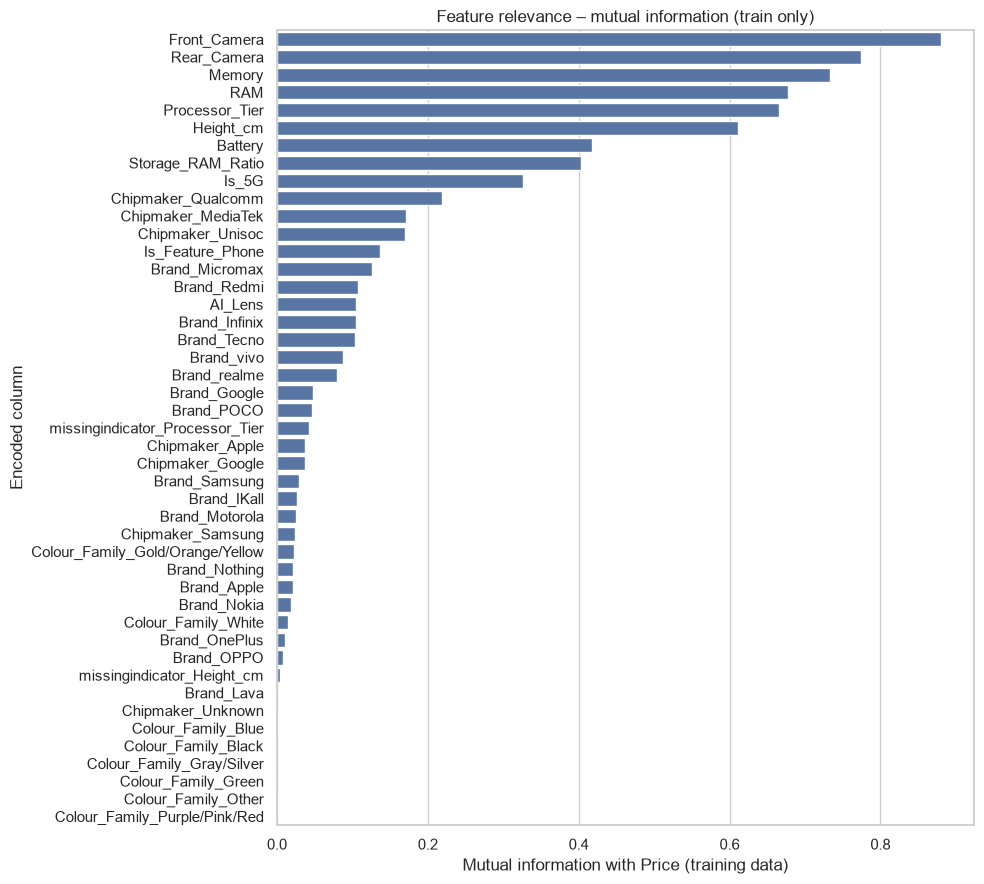

Columns kept (MI > 0.03): 25 of 45
Dropped: ['Brand_Samsung', 'Brand_IKall', 'Brand_Motorola', 'Chipmaker_Samsung', 'Colour_Family_Gold/Orange/Yellow', 'Brand_Nothing', 'Brand_Apple', 'Brand_Nokia', 'Colour_Family_White', 'Brand_OnePlus', 'Brand_OPPO', 'missingindicator_Height_cm', 'Brand_Lava', 'Chipmaker_Unknown', 'Colour_Family_Blue', 'Colour_Family_Black', 'Colour_Family_Gray/Silver', 'Colour_Family_Green', 'Colour_Family_Other', 'Colour_Family_Purple/Pink/Red']


In [44]:
mi = mutual_info_regression(Xt_train, y_train, random_state=RANDOM_STATE)
mi_s = pd.Series(mi, index=[n.split("__", 1)[1] for n in feat_names]).sort_values(ascending=False)
plt.figure(figsize=(10, 9))
sns.barplot(x=mi_s.values, y=mi_s.index, color="#4C72B0")
plt.xlabel("Mutual information with Price (training data)"); plt.ylabel("Encoded column"); plt.title("Feature relevance – mutual information (train only)")
save_show("12_mutual_information")
MI_THRESHOLD = 0.03
K = int((mi_s > MI_THRESHOLD).sum())
print(f"Columns kept (MI > {MI_THRESHOLD}): {K} of {len(mi_s)}")
print("Dropped:", mi_s[mi_s <= MI_THRESHOLD].index.tolist())

**Interpretation (training data only)**
- At the level of the original feature, the highest mutual information with price is: Front_Camera (0.88), Rear_Camera (0.77), Memory (0.73), RAM (0.68), Processor_Tier (0.67), Height_cm (0.61), then Battery (0.42), Storage_RAM_Ratio (0.40) and Is_5G (0.33).
- **All colour columns are ≤ 0.022** → they carry practically no information about price.
- Individual brand columns have low MI because each brand is a rare 0/1 column (e.g. only 5 Apple rows). With the 0.03 threshold, **25 of the 45 encoded columns are kept**; the dropped ones are mostly colour and rare-brand columns. This is a limitation: a rare brand such as Apple is informative for the few phones it covers, but cannot show it in this statistic.

The threshold was read from the **training** set. In every modelling pipeline below, the selection step (`SelectKBest` with mutual information) is **re-fitted inside each cross-validation fold**, so no information from validation or test rows is used.

### 5.3 PCA – exploratory dimensionality reduction (training data)

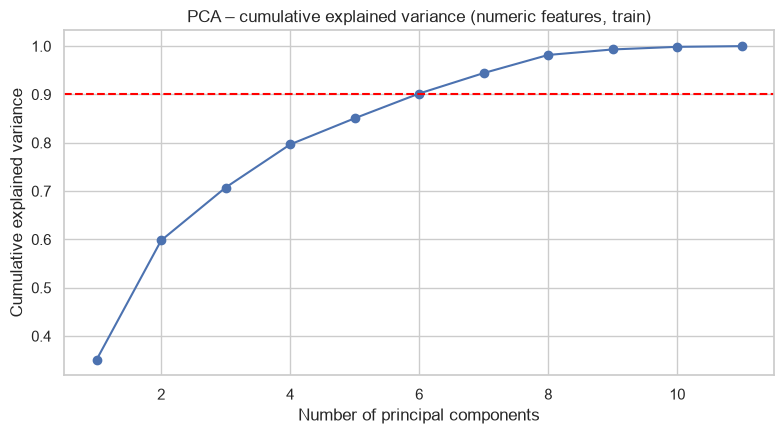

Components needed for 90% variance: 6 of 11
                    PC1   PC2
Memory             0.38 -0.27
RAM                0.34 -0.21
Battery            0.18  0.53
Rear_Camera        0.37 -0.02
Front_Camera       0.36 -0.09
AI_Lens           -0.06  0.12
Height_cm          0.27  0.51
Processor_Tier     0.37 -0.18
Is_5G              0.35 -0.12
Is_Feature_Phone  -0.25 -0.50
Storage_RAM_Ratio  0.19 -0.14


In [45]:
num_only = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_train[num_cols])
pca = PCA().fit(num_only.transform(X_train[num_cols]))
cum = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(0.9, color="red", ls="--"); plt.xlabel("Number of principal components"); plt.ylabel("Cumulative explained variance")
plt.title("PCA – cumulative explained variance (numeric features, train)")
save_show("13_pca")
print("Components needed for 90% variance:", int(np.argmax(cum >= 0.9)) + 1, "of", len(cum))
print(pd.DataFrame(pca.components_[:2], columns=num_cols, index=["PC1", "PC2"]).T.round(2))

**Interpretation (PCA is exploratory)**
- **6 of the 11 numeric features** are needed for 90 % of the variance, so the features are not very redundant and PCA would compress the data only modestly.
- PC1 combines Memory, Processor_Tier, cameras and 5G (loadings 0.34–0.38): an "overall spec level" axis. PC2 contrasts Battery and Height with the feature-phone flag: a "size/battery" axis.
- PCA was used to investigate dimensionality reduction only. The final models keep the original, interpretable features, because the project aims both to predict price *and* to identify which specifications matter.

## Step 6 – Model building with one leak-free pipeline
Every model is the same pipeline: **impute → scale → one-hot encode → select features (MI) → model**. Models start simple and get more complex only if they pay off:

| Model | Why it is included |
|---|---|
| Linear Regression | Simplest baseline |
| Ridge Regression (raw and log price) | Linear model with regularisation; the log version fits *percentage* price differences |
| Gradient Boosting | Trees fitted one after another to fix earlier errors |

Price is right-skewed, so Ridge is also tried on `log(price)`. Boosted trees did not benefit from the log transform in earlier tests, so they use the raw price.

**Why a short model list?** Following the instructor's guidance, the comparison is kept small (linear baselines plus boosting). Random Forest and Decision Tree were tried in an earlier version of this notebook – Random Forest was statistically tied with the boosting model (nested RMSE ₹5,919) – and were dropped from the final comparison. XGBoost was also tested (nested RMSE ₹5,631, statistically tied) and removed to keep the number of libraries minimal – scikit-learn's Gradient Boosting is the same family of model.

In [46]:
mi_func = partial(mutual_info_regression, random_state=RANDOM_STATE)

def make_pipe(estimator, log_target=False):
    pipe = Pipeline([("prep", build_preprocessor()),
                     ("select", SelectKBest(mi_func, k=K)),
                     ("model", estimator)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe

def p(prefix, log):   # parameter-name prefix for the model step
    return ("regressor__" if log else "") + "model__"

candidates = {   # name -> (pipeline, tuning grid)
    "Linear Regression":     (make_pipe(LinearRegression()), {}),
    "Ridge (raw price)":     (make_pipe(Ridge()), {p("", False) + "alpha": [0.1, 1, 10, 30]}),
    "Ridge (log price)":     (make_pipe(Ridge(), log_target=True), {p("", True) + "alpha": [0.1, 1, 10, 30]}),
    "Gradient Boosting":     (make_pipe(GradientBoostingRegressor(random_state=RANDOM_STATE)),
                              {p("", False) + "n_estimators": [200, 400], p("", False) + "learning_rate": [0.05, 0.1], p("", False) + "max_depth": [2, 3]}),
}
print({k: len(v[1]) for k, v in candidates.items()})

{'Linear Regression': 0, 'Ridge (raw price)': 1, 'Ridge (log price)': 1, 'Gradient Boosting': 3}


### 6.1 Nested cross-validation (unbiased comparison)
Tuning hyper-parameters and then reporting the *same* cross-validation score is optimistic. In **nested** cross-validation the outer loop (5 folds, grouped by phone model) measures performance, while the inner loop (3 folds) only chooses the hyper-parameters on the outer-training part.

In [47]:
outer = GroupKFold(n_splits=5)
rows, fold_rmse = [], {}
for name, (pipe, grid) in candidates.items():
    est = GridSearchCV(pipe, grid, cv=GroupKFold(n_splits=3), scoring="neg_root_mean_squared_error", n_jobs=-1) if grid else pipe
    res = cross_validate(est, X_train, y_train, groups=g_train, cv=outer, params={"groups": g_train} if grid else None,
                         scoring=("neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"))
    fold_rmse[name] = -res["test_neg_root_mean_squared_error"]
    rows.append({"Model": name, "Nested CV RMSE (₹)": fold_rmse[name].mean(), "± std": fold_rmse[name].std(),
                 "Nested CV MAE (₹)": -res["test_neg_mean_absolute_error"].mean(), "Nested CV R²": res["test_r2"].mean()})
nested = pd.DataFrame(rows).set_index("Model").round(3).sort_values("Nested CV RMSE (₹)")
nested

,Nested CV RMSE (₹),± std,Nested CV MAE (₹),Nested CV R²
Model,,,,
Ridge (log price),6289.789,3524.531,3265.916,0.669
Gradient Boosting,6321.693,2566.662,3369.159,0.657
Ridge (raw price),6406.694,2916.248,4034.086,0.654
Linear Regression,6742.109,2759.691,4228.989,0.614


**Interpretation (nested cross-validation, grouped by phone model)**
- **Ridge (log price) has the lowest nested-CV RMSE (₹6,290; MAE ₹3,266; R² 0.669)**, followed by Gradient Boosting (₹6,322; R² 0.657), Ridge on raw price (₹6,407) and Linear Regression (₹6,742).
- The gap between the top two is only ₹32 while the fold-to-fold standard deviation is ₹2,600–3,500, so they are **statistically tied**. Ridge (log price) is selected by the pre-agreed rule (lowest nested-CV RMSE), not because it is clearly better.
- The log transform helps Ridge a little (₹6,407 → ₹6,290) because prices behave in percentages.

### 6.2 Tune on the full training set, then check stability with repeated grouped validation

In [48]:
tuned = {}
for name, (pipe, grid) in candidates.items():
    if grid:
        gs = GridSearchCV(pipe, grid, cv=GroupKFold(n_splits=5), scoring="neg_root_mean_squared_error", n_jobs=-1)
        gs.fit(X_train, y_train, groups=g_train); tuned[name] = gs.best_estimator_
        print(f"{name:20s} best params: { {k.split('model__')[1]: v for k, v in gs.best_params_.items()} }")
    else:
        tuned[name] = clone(pipe)

# 20 different random group partitions of the training set
rep = GroupShuffleSplit(n_splits=20, test_size=0.25, random_state=RANDOM_STATE)
rep_rmse = {}
for name in ["Gradient Boosting", "Ridge (log price)", "Linear Regression"]:
    r = cross_validate(clone(tuned[name]), X_train, y_train, groups=g_train, cv=rep, scoring="neg_root_mean_squared_error", n_jobs=-1)
    rep_rmse[name] = -r["test_score"]
rep_tab = pd.DataFrame({n: {"Mean RMSE (₹)": v.mean(), "Std (₹)": v.std()} for n, v in rep_rmse.items()}).T.round(0)
diff = rep_rmse["Gradient Boosting"] - rep_rmse["Ridge (log price)"]
print(rep_tab)
print(f"\nGradient Boosting minus Ridge(log) RMSE: mean {diff.mean():+.0f} ₹, std {diff.std():.0f} ₹; GB better in {(diff < 0).sum()} of 20 splits")

Ridge (raw price)    best params: {'alpha': 10}
Ridge (log price)    best params: {'alpha': 1}
Gradient Boosting    best params: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
                   Mean RMSE (₹)  Std (₹)
Gradient Boosting         6382.0   2495.0
Ridge (log price)         6265.0   2648.0
Linear Regression         7025.0   2034.0

Gradient Boosting minus Ridge(log) RMSE: mean +117 ₹, std 1175 ₹; GB better in 10 of 20 splits


**Interpretation (20 random group partitions of the training set)**
- Gradient Boosting averages ₹6,382 RMSE, Ridge (log) ₹6,265 and Linear Regression ₹7,025, with a standard deviation of ₹2,000–2,650 between splits.
- The paired difference between Gradient Boosting and Ridge (log) is +₹117 (std ₹1,175) and Gradient Boosting wins only 10 of 20 splits – **a coin-flip**. The simple model is as good as the boosted one on this small data set.
- Practical consequence: the choice between the top models should also consider explainability, not only the score.

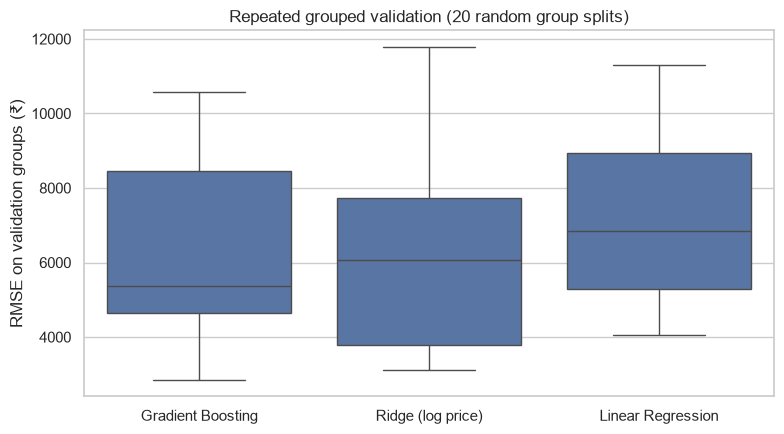

In [49]:
plt.figure(figsize=(8, 4.5))
sns.boxplot(data=pd.DataFrame(rep_rmse), color="#4C72B0")
plt.ylabel("RMSE on validation groups (₹)"); plt.title("Repeated grouped validation (20 random group splits)")
save_show("14_repeated_cv")

### 6.3 Check: label encoding vs one-hot encoding for `Brand`
A common rule of thumb is that one-hot encoding "increases the dimension" and label encoding keeps one column. For a **nominal** column such as Brand, label encoding invents an order (Apple = 0 … vivo = 18), which can mislead linear models; tree models can live with it. Instead of arguing, we test both on the training data (same 20 grouped splits, no feature-selection step so that only the encoding differs).

In [50]:
from sklearn.preprocessing import OrdinalEncoder

def pipe_with_brand_encoding(encoding, estimator, log_target=False):
    numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())
    brand_enc = (OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1) if encoding == "label"
                 else OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    pre = ColumnTransformer([("num", numeric, num_cols), ("brand", brand_enc, ["Brand"]),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Chipmaker", "Colour_Family"])])
    pipe = Pipeline([("prep", pre), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1) if log_target else pipe

gb_best = tuned["Gradient Boosting"].named_steps["model"]
ridge_best = tuned["Ridge (log price)"].regressor.named_steps["model"]
rows = []
for enc in ["one-hot", "label"]:
    for mname, est, lg in [("Gradient Boosting", gb_best, False), ("Ridge (log price)", ridge_best, True)]:
        r = cross_validate(pipe_with_brand_encoding("label" if enc == "label" else "onehot", clone(est), lg), X_train, y_train,
                           groups=g_train, cv=rep, scoring="neg_root_mean_squared_error", n_jobs=-1)
        rows.append({"Brand encoding": enc, "Model": mname, "Mean RMSE (₹)": -r["test_score"].mean(), "Std (₹)": r["test_score"].std()})
brand_enc_tab = pd.DataFrame(rows).set_index(["Model", "Brand encoding"]).round(0)
brand_enc_tab

,,Mean RMSE (₹),Std (₹)
Model,Brand encoding,,
Gradient Boosting,one-hot,6307.0,2455.0
Ridge (log price),one-hot,5427.0,1937.0
Gradient Boosting,label,6601.0,2292.0
Ridge (log price),label,5675.0,2225.0


**Interpretation – label vs one-hot encoding of Brand**
- One-hot encoding gives a **slightly lower error for both models**: Gradient Boosting ₹6,307 vs ₹6,601 with label encoding, Ridge (log) ₹5,427 vs ₹5,675.
- The differences (₹250–300) are small compared with the split-to-split spread (₹1,900–2,500), so label encoding would not be a disaster for tree models – but there is **no evidence that it is better**, and for Ridge it assumes a false order between brands.
- The "one-hot increases dimension" concern is real but small here: Brand adds 19 columns to a data set with 531 rows, and the mutual-information filter inside the pipeline removes the weakest ones. Decision: **keep one-hot**, and be ready to quote this table when asked.

## Step 7 – Final evaluation on the untouched test set
The models are fitted on the full training set with the tuned hyper-parameters and evaluated on the 101 test phones as the final, independent evaluation. The *selected* model is decided from the training-set evidence (nested and repeated validation), not from these test scores. **Role of the test set:** besides this final evaluation it is also used *for interpretation only* – the price-segment table, the residual plot and the permutation importance in Step 8. None of these results was used to select the model, choose features or tune hyper-parameters.

In [51]:
def rmse(a, b): return np.sqrt(mean_squared_error(a, b))
rows, preds = [], {}
for name, mdl in tuned.items():
    mdl.fit(X_train, y_train)
    pr = mdl.predict(X_test); preds[name] = pr
    rows.append({"Model": name, "Test MAE (₹)": mean_absolute_error(y_test, pr), "Test RMSE (₹)": rmse(y_test, pr), "Test R²": r2_score(y_test, pr)})
results = pd.DataFrame(rows).set_index("Model").round(3)
results = nested[["Nested CV RMSE (₹)"]].join(results).sort_values("Nested CV RMSE (₹)")
best_name = results.index[0]
print("Selected by nested CV (lowest RMSE):", best_name, "| runner-up:", results.index[1])
results

Selected by nested CV (lowest RMSE): Ridge (log price) | runner-up: Gradient Boosting


,Nested CV RMSE (₹),Test MAE (₹),Test RMSE (₹),Test R²
Model,,,,
Ridge (log price),6289.789,2111.131,3503.128,0.860
Gradient Boosting,6321.693,2894.408,4293.679,0.790
Ridge (raw price),6406.694,3395.521,4492.830,0.770
Linear Regression,6742.109,2919.748,4229.431,0.797


**Interpretation**
- By the pre-agreed rule (lowest nested-CV RMSE) **Ridge (log price) is selected**; Gradient Boosting is the runner-up. The two are a near tie (₹6,290 vs ₹6,322) relative to the fold-to-fold spread.
- On the 101 unseen test phones, **Ridge (log price) scores R² 0.86 (MAE ₹2,111, RMSE ₹3,503)**; Gradient Boosting 0.79 (MAE ₹2,894, RMSE ₹4,294); Linear Regression 0.80 (MAE ₹2,920); Ridge (raw price) 0.77 (MAE ₹3,396). The model was **not** selected from these test scores – the test ranking merely agrees with the cross-validation choice.
- Honest range: cross-validation R² is about 0.67 and the test R² 0.86, so roughly **67–86 %** of the price variation of unseen phone models is explained; the test set has only 101 phones, so the upper figure is less certain.
- A simple, explainable model is as good as the boosted one, which is a useful finding in itself.

### 7.1 Errors by price segment (selected model and the runner-up)

In [52]:
bins = pd.cut(y_test, [0, 10000, 30000, np.inf], labels=["Budget (< ₹10k)", "Mid-range (₹10–30k)", "Premium (> ₹30k)"])
def seg_table(name):
    pr = preds[name]; out = []
    for seg in bins.cat.categories:
        m = (bins == seg).values
        if m.sum() == 0: continue
        out.append({"Model": name, "Segment": seg, "Phones": int(m.sum()),
                    "MAE (₹)": mean_absolute_error(y_test[m], pr[m]), "RMSE (₹)": rmse(y_test[m], pr[m]),
                    "Median abs % error": np.median(np.abs(y_test[m] - pr[m]) / y_test[m]) * 100,
                    "Mean error (actual − predicted)": (y_test[m] - pr[m]).mean()})
    return pd.DataFrame(out)
seg = pd.concat([seg_table(best_name), seg_table("Ridge (log price)")] if best_name != "Ridge (log price)" else [seg_table(best_name)]).round(1)
seg

,Model,Segment,Phones,MAE (₹),RMSE (₹),Median abs % error,Mean error (actual − predicted)
0,Ridge (log price),Budget (< ₹10k),24,1254.8,1473.7,18.6,-156.1
1,Ridge (log price),Mid-range (₹10–30k),66,1595.3,2125.6,8.6,15.9
2,Ridge (log price),Premium (> ₹30k),11,7074.8,8990.7,24.7,7049.8


**Interpretation (selected model: Ridge on log price)**
- **Budget (24 phones):** MAE ₹1,255, median error 18.6 %. The percentage error is highest here because prices are low – the same rupee error is a bigger share of a ₹8,000 phone.
- **Mid-range (66 phones):** MAE ₹1,595, median error 8.6 % – the model's best segment.
- **Premium (11 phones):** the weak spot – MAE ₹7,075 (median error 24.7 %), and the average signed error (+₹7,050) is almost equal to the MAE, so **almost every premium phone is under-predicted**.
- Reason: very few premium phones in the data (46 in total), so the model has little to learn from. The headline test metrics **hide a larger premium-segment error** – and with 11 phones this estimate is itself uncertain.

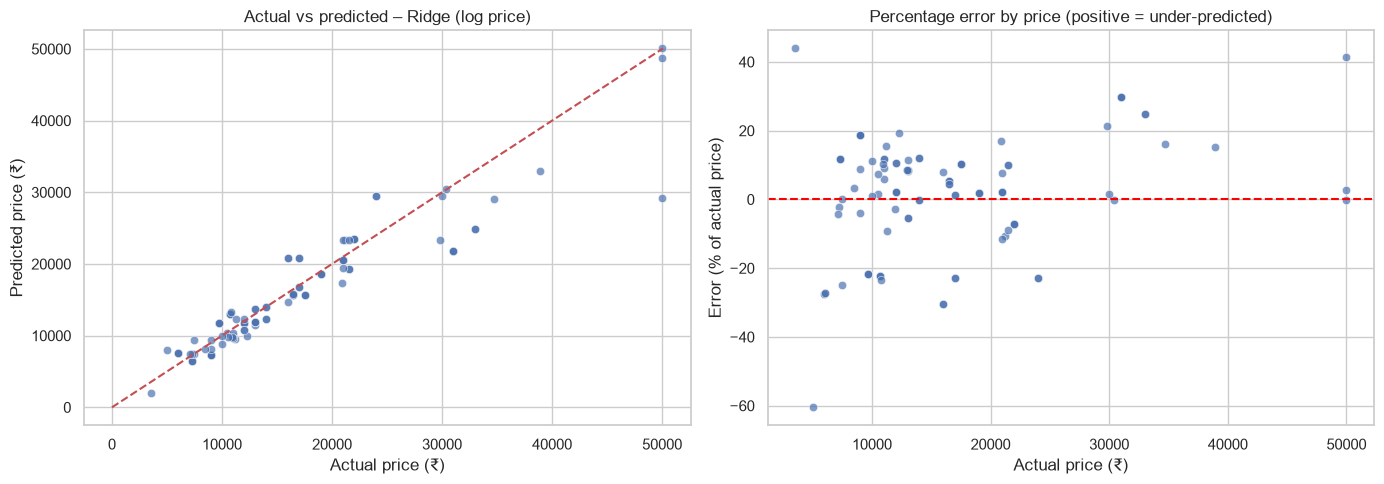

Median absolute error: ₹1,298 | MdAPE: 10.3%
Within ±₹3,000: 83% | within ±20%: 74%


In [53]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
bp = preds[best_name]
sns.scatterplot(x=y_test, y=bp, ax=ax[0], alpha=0.7)
lim = [0, max(y_test.max(), bp.max())]
ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual price (₹)"); ax[0].set_ylabel("Predicted price (₹)")
ax[0].set_title(f"Actual vs predicted – {best_name}")
res_ = y_test.values - bp
sns.scatterplot(x=y_test, y=res_ / y_test.values * 100, ax=ax[1], alpha=0.7)
ax[1].axhline(0, color="red", ls="--"); ax[1].set_xlabel("Actual price (₹)"); ax[1].set_ylabel("Error (% of actual price)")
ax[1].set_title("Percentage error by price (positive = under-predicted)")
save_show("15_actual_vs_predicted")
print(f"Median absolute error: ₹{np.median(np.abs(res_)):,.0f} | MdAPE: {np.median(np.abs(res_) / y_test.values) * 100:.1f}%")
print(f"Within ±₹3,000: {(np.abs(res_) <= 3000).mean():.0%} | within ±20%: {(np.abs(res_) / y_test.values <= 0.2).mean():.0%}")

**Interpretation (selected model: Ridge on log price)**
- The predictions follow the diagonal closely up to about ₹30,000; for the most expensive phones the model **under-predicts** (right chart: positive percentage errors at high prices).
- Overall: median absolute error ₹1,298 (10.3 % of the price); 83 % of predictions within ±₹3,000 and 74 % within ±20 %.
- **Do not read the overall figures as uniform accuracy** – see the segment table above.

In [54]:
# Does the leakage matter? Same pipeline and data, only the way the folds are built differs
from sklearn.model_selection import KFold, cross_val_score
rows = []
for label, cv_ in [("Random row folds (leaky)", KFold(5, shuffle=True, random_state=RANDOM_STATE)),
                   ("Grouped-by-model folds (honest)", GroupKFold(5))]:
    kw = dict(groups=groups, cv=cv_, n_jobs=-1)
    r2s = cross_val_score(clone(tuned[best_name]), X, y, scoring="r2", **kw)
    rm = -cross_val_score(clone(tuned[best_name]), X, y, scoring="neg_root_mean_squared_error", **kw)
    rows.append({"Validation scheme": label, "R²": r2s.mean(), "RMSE (₹)": rm.mean()})
leak_tab = pd.DataFrame(rows).set_index("Validation scheme").round(3)
leak_tab

C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


,R²,RMSE (₹)
Validation scheme,,
Random row folds (leaky),0.734,5516.141
Grouped-by-model folds (honest),0.699,5897.145


**Interpretation (selected model: Ridge on log price)**
- With ordinary random folds the model scores R² 0.734 (RMSE ₹5,516); with folds grouped by phone model it scores **R² 0.699 (RMSE ₹5,897)**.
- The gap is modest for this simple linear model, but it still shows that random folds are optimistic: the same phone appears in several colours at the same price, so a random split lets the model "recognise" a phone it has already seen. Flexible tree models are expected to be affected more. All decisions here use the grouped scheme. (This cell uses all rows and is an illustration only – it changed no decision.)

## Step 8 – Feature importance (recomputed with one-hot Brand)
Because categories are now one-hot encoded, importance is **aggregated back to the original feature** (e.g. all brand columns together). Three views:
1. **Permutation importance on the test set (interpretation only – it does not change the selected model, the features or the tuning)** – shuffle one *original* column (e.g. Brand as a whole) and measure the drop in R². Computed for the selected tree model and for Ridge (log price).
2. **Impurity importance of the selected tree model**, summed over the columns of each original feature.
3. **Mutual information** (training data), maximum over the columns of each original feature.

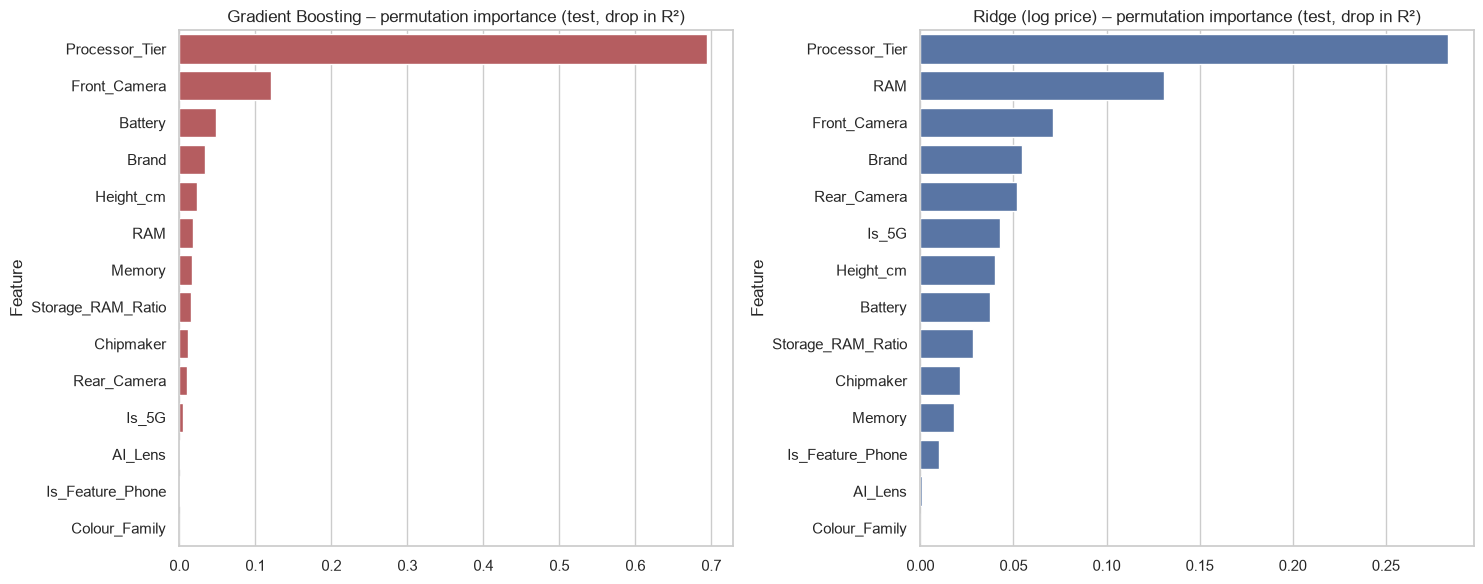

,Tree impurity,Tree permutation,Ridge(log) permutation,Mutual information
Processor_Tier,0.480,0.694,0.283,0.666
Front_Camera,0.149,0.120,0.071,0.880
Battery,0.084,0.048,0.037,0.418
Brand,0.009,0.034,0.055,0.126
Height_cm,0.022,0.023,0.040,0.612
RAM,0.018,0.018,0.131,0.678
Memory,0.056,0.017,0.018,0.733
Storage_RAM_Ratio,0.008,0.015,0.028,0.403
Chipmaker,0.118,0.011,0.022,0.219
Rear_Camera,0.024,0.010,0.052,0.774


In [55]:
def orig_name(col):
    c = col.split("__", 1)[1]
    c = c.replace("missingindicator_", "")
    for cat in cat_cols:
        if c.startswith(cat + "_"): return cat
    return c

def perm_importance(name):
    return pd.Series(permutation_importance(tuned[name], X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="r2").importances_mean,
                     index=X.columns)

tree_name = "Gradient Boosting"
gb_pipe = tuned[tree_name]
sel_names = gb_pipe.named_steps["prep"].get_feature_names_out()[gb_pipe.named_steps["select"].get_support()]
gb_imp = pd.Series(gb_pipe.named_steps["model"].feature_importances_, index=[orig_name(n) for n in sel_names]).groupby(level=0).sum()
perm_gb = perm_importance(tree_name)
perm_ridge = perm_importance("Ridge (log price)")
mi_orig = mi_s.groupby([orig_name("x__" + n) for n in mi_s.index]).max()

imp_tab = pd.DataFrame({"Tree impurity": gb_imp, "Tree permutation": perm_gb, "Ridge(log) permutation": perm_ridge, "Mutual information": mi_orig}).fillna(0)
imp_tab = imp_tab.sort_values("Tree permutation", ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(x=perm_gb.sort_values(ascending=False).values, y=perm_gb.sort_values(ascending=False).index, ax=ax[0], color="#C44E52")
ax[0].set_title(f"{tree_name} – permutation importance (test, drop in R²)"); ax[0].set_ylabel("Feature")
sns.barplot(x=perm_ridge.sort_values(ascending=False).values, y=perm_ridge.sort_values(ascending=False).index, ax=ax[1], color="#4C72B0")
ax[1].set_title("Ridge (log price) – permutation importance (test, drop in R²)"); ax[1].set_ylabel("Feature")
save_show("16_feature_importance")
imp_tab.round(3)

**Interpretation (Gradient Boosting impurity and permutation, and Ridge (log) permutation, with one-hot Brand)**
- **Processor_Tier is the top feature** in every view – permutation importance 0.69 for Gradient Boosting and 0.28 for Ridge (shuffling it alone costs 28–69 points of R²).
- **Front_Camera** is second for Gradient Boosting (0.120; Ridge 0.071). For the selected Ridge model, **RAM (0.131)** is second, then Front_Camera (0.071), Brand (0.055) and Rear_Camera (0.052). Correlated features (RAM, Memory, cameras) split the credit differently between models.
- **Brand** is a small but steady contributor (0.034 Gradient Boosting, 0.055 Ridge).
- **Chipmaker** looks important by impurity (0.118) but falls to 0.011 by permutation – impurity importance over-rewards columns with several overlapping categories. AI_Lens, Colour_Family and Is_Feature_Phone add nothing; Rear_Camera matters for Ridge (0.052) but not for Gradient Boosting (0.010).
- Test-set permutation importance is **for interpretation only** and changed no model, feature or tuning choice.

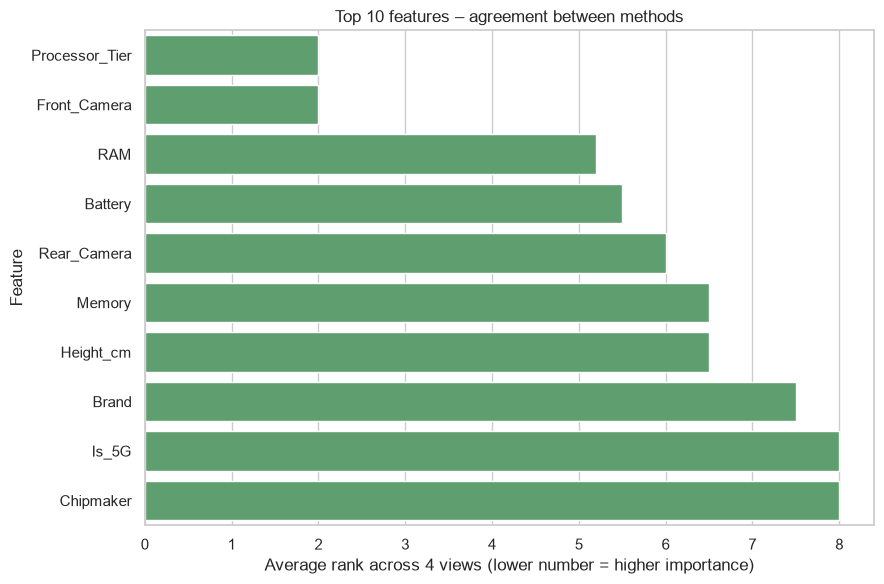

,Tree impurity,Tree permutation,Ridge(log) permutation,Mutual information,Average rank
Processor_Tier,1,1,1,5,2.0
Front_Camera,2,2,3,1,2.0
RAM,9,6,2,4,5.2
Battery,4,3,8,7,5.5
Rear_Camera,7,10,5,2,6.0
Memory,5,7,11,3,6.5
Height_cm,8,5,7,6,6.5
Brand,10,4,4,12,7.5
Is_5G,6,11,6,9,8.0
Chipmaker,3,9,10,10,8.0


In [56]:
rank = pd.DataFrame({c: imp_tab[c].rank(ascending=False) for c in imp_tab.columns}).astype(int)
rank["Average rank"] = rank.mean(axis=1).round(1)
rank = rank.sort_values("Average rank")
plt.figure(figsize=(9, 6))
top = rank.head(10)["Average rank"]
sns.barplot(x=top.values, y=top.index, color="#55A868")
plt.xlabel("Average rank across 4 views (lower number = higher importance)"); plt.ylabel("Feature"); plt.title("Top 10 features – agreement between methods")
save_show("17_rank_agreement")
rank

**Interpretation**
- Average rank over the four views: **Processor_Tier (2.0) and Front_Camera (2.0)**, then RAM (5.2), Battery (5.5), Rear_Camera (6.0), Memory and Height (6.5), Brand (7.5), Is_5G and Chipmaker (8.0). Is_Feature_Phone (12.0), AI_Lens (12.8) and Colour_Family (14.0) are at the bottom.
- The methods **disagree in the middle of the table** (e.g. Rear_Camera is #2 by mutual information but #10 by Gradient Boosting permutation). With correlated features this is expected – only the *top* (processor tier, front camera) and *bottom* (colour, AI lens) are firm conclusions.
- Front camera, battery and height behave as proxies for the market segment; they are associated with price, not necessarily the reason for it.

### Three kinds of features (important for interpretation)
*A feature that helps predict price is not necessarily a feature that **causes** the price.*

| Category | Features | Interpretation |
|---|---|---|
| **Strong predictive signals** | see table above (processor tier, memory …) | Directly useful for estimating a phone's price |
| **May reflect the market segment** | Front camera, Height, Battery | Help to tell budget from premium phones, but are probably not the *reason* for the price |
| **Little additional value** | Colour family, AI lens, rear camera (in this data) | Add nothing once the other features are known |

## Step 9 – Recommendations (price-benchmarking, not price-optimisation)

The model is a **price-benchmarking aid**, not a pricing-optimisation system: it predicts *price*, not demand, sales or profit.

| Business objective | Suggested action (from this analysis) | Metric to monitor |
|---|---|---|
| Set initial price benchmarks | Compare a new phone with phones of the **same processor tier** (median ₹7,999 / ₹13,999 / ₹23,999 / ₹33,844 for tiers 0–3) | Prediction error by processor tier |
| Plan storage variants | Median price is ₹9,999 (64 GB), ₹16,999 (128 GB), ₹29,999 (256 GB); use the gaps as a guide for variant price steps | Price gap between variants vs gap in sales |
| 5G positioning | 5G phones have a median of ₹19,999 vs ₹9,999 for 4G (partly because 5G comes with better chips) – a mid-range-and-up feature | Share of 5G in each price band |
| Premium phones | **Do not rely on the model above ₹30,000**: it under-predicted the premium test phones (average error ₹9,336 for 11 phones). More premium data is a sensible next experiment, not a guaranteed fix | MAE for phones above ₹30,000 |
| Features not to price on | Colour, AI lens and rear-camera megapixels added little predictive value; colour decisions should also use demand, inventory and sales data | Sell-through by colour (needs sales data) |
| Keep the model reliable | Retrain as new models launch; compare predicted and real prices | Monthly MAE and RMSE |

Inventory, margin and sell-through metrics need sales data that this data set does not contain.

## Step 10 – Save the model and predict a phone's price
The selected pipeline (imputation → encoding → feature selection → model) is **re-fitted on all 531 rows** and saved with `pickle`, so it can be loaded later without re-training. Its expected accuracy is the one measured above (nested CV and test set) – re-fitting on all rows does not give a new accuracy figure.

The prediction function re-creates the same engineered features (brand, chipmaker, processor tier, 5G flag …) and adds **guard rails**: it warns if the processor is not recognised and if the estimate falls in the premium range, where the model was found to be unreliable.

In [57]:
deploy_model = clone(tuned[best_name]).fit(X, y)
with open("mobile_price_model.pkl", "wb") as f:
    pickle.dump(deploy_model, f)
with open("mobile_price_model.pkl", "rb") as f:
    loaded_model = pickle.load(f)
print(f"Saved: mobile_price_model.pkl  ({best_name}, fitted on all {len(X)} rows)")

seg_mae = seg_table(best_name).set_index("Segment")["MAE (₹)"].to_dict()      # typical test error per price segment
known_brands = set(df["Brand"])

def predict_phone_price(brand, colour, memory, ram, battery, rear_camera, front_camera, height_cm, processor,
                        model_name="", ai_lens=0, model=loaded_model):
    """Estimate a benchmark price from the specifications. Returns the estimate and any warnings."""
    notes = []
    brand_clean = get_brand(brand)
    if brand_clean == "Other":
        brand_clean = get_brand(model_name)
    if brand_clean not in known_brands:
        notes.append(f"Brand '{brand}' is not in the training data - the brand effect is ignored.")
    proc = {"Brand": brand_clean, "Processor": str(processor).strip() or "unknown"}
    chipmaker = get_chipmaker(proc)
    tier = get_tier({**proc, "Chipmaker": chipmaker})
    if pd.isna(tier):
        notes.append("Processor not recognised - processor tier is filled with the training median (less reliable).")
    text = (str(model_name) + " " + proc["Processor"]).lower()
    row = {"Memory": float(memory), "RAM": float(ram), "Battery": float(battery), "Rear_Camera": float(rear_camera),
           "Front_Camera": float(front_camera), "AI_Lens": int(ai_lens), "Height_cm": float(height_cm),
           "Processor_Tier": tier, "Is_5G": int("5g" in text or "dimensity" in text),
           "Is_Feature_Phone": int(float(height_cm) < 10), "Storage_RAM_Ratio": float(memory) / float(ram),
           "Brand": brand_clean, "Chipmaker": chipmaker, "Colour_Family": colour_family(str(colour).strip())}
    price = max(0.0, float(model.predict(pd.DataFrame([row], columns=num_cols + cat_cols))[0]))
    segment = "Budget (< ₹10k)" if price < 10000 else ("Mid-range (₹10–30k)" if price <= 30000 else "Premium (> ₹30k)")
    if segment.startswith("Premium"):
        notes.append("Premium range: in testing, every premium phone was under-predicted - treat this as a lower bound.")
    return {"Estimated price (₹)": round(price, -1), "Segment": segment,
            "Typical test error in this segment (₹)": round(seg_mae.get(segment, float("nan")), -1), "Notes": " | ".join(notes) or "-"}

examples = {
    "Samsung Galaxy A55 5G": dict(brand="Samsung", model_name="Samsung Galaxy A55 5G", colour="Awesome Navy", memory=128, ram=8,
                                              battery=5000, rear_camera=50, front_camera=32, height_cm=16.5, processor="Exynos 1480"),
    "Redmi budget phone": dict(brand="Redmi", model_name="Redmi 12", colour="Midnight Black", memory=64, ram=4,
                               battery=5000, rear_camera=50, front_camera=8, height_cm=16.8, processor="MediaTek Helio G88"),
    "Apple iPhone 14 Plus (in the training data)": dict(brand="Apple", model_name="Apple iPhone 14 Plus", colour="Midnight", memory=128, ram=6,
                                       battery=4323, rear_camera=12, front_camera=12, height_cm=16.0, processor="iOS A15 Bionic"),
}
pred_table = pd.DataFrame({name: predict_phone_price(**spec) for name, spec in examples.items()}).T
pred_table

Saved: mobile_price_model.pkl  (Ridge (log price), fitted on all 531 rows)


,Estimated price (₹),Segment,Typical test error in this segment (₹),Notes
Samsung Galaxy A55 5G,27270.0,Mid-range (₹10–30k),1600.0,-
Redmi budget phone,10930.0,Mid-range (₹10–30k),1600.0,-
Apple iPhone 14 Plus (in the training data),52750.0,Premium (> ₹30k),7070.0,"Premium range: in testing, every premium phone..."


**Interpretation**
- The saved model (`mobile_price_model.pkl`) is the Ridge (log price) pipeline re-fitted on all 531 rows; its accuracy is the one measured above, not a new figure.
- **Redmi budget phone → ₹10,930**; typical test error in the segment about ₹1,600.
- **Samsung Galaxy A55 5G → ₹27,270**, labelled mid-range **with no warning**. Its real launch price was higher (about ₹40,000), so this is an under-estimate of roughly a third. The premium guard-rail only fires when the *estimate itself* is above ₹30,000, so it misses this case – estimates for high-end phones should be treated as lower bounds.
- **iPhone 14 Plus → ₹52,750** (real ₹80,999), flagged as premium. This phone is part of the training data, so even an in-sample example is clearly under-estimated – a further sign of the premium weakness.
- The function warns about unknown brands, unrecognised processors and premium-range estimates instead of failing silently.

## Conclusion and limitations

**What we did:** cleaned a messy 541-row data set (10 duplicates removed, 2 impossible heights set to missing, camera text converted), engineered and validated new features (brand, processor tier, chipmaker, colour family, 5G, feature-phone flag), explored price segments, and compared four models with **leak-free pipelines** (imputation, scaling, one-hot encoding and feature selection fitted on training data only), **nested** and **repeated** grouped cross-validation, and a final test evaluation. The selected pipeline is saved (`mobile_price_model.pkl`) and wrapped in a prediction function with guard rails.

**Main findings**
- Processor class is the strongest driver of price in every view; front camera, RAM, battery and 5G follow; colour and AI lens add little.
- Ridge (log price) and Gradient Boosting are statistically tied (nested RMSE ₹6,290 vs ₹6,322); Ridge (log price) is selected by the rule and also scores best on the test set (R² 0.86, MAE ₹2,111). Cross-validation R² is about 0.67, so roughly 67–86 % of the price variation of unseen phone models is explained.
- The **segment analysis exposes the key weakness:** mid-range phones are predicted within about 9 % (median), budget phones within ₹1,255 on average, but the 11 premium test phones are almost all under-predicted (average error ₹7,075).

**Limitations**
- Only 531 rows (187 models) and few premium phones (46); the 101-phone test set is small, so rankings among the top models are uncertain. Because the top models are so close, their order can change with a different software version or random split; the numbers in this notebook are those of the saved run.
- Some entries are doubtful (cheap phones with high RAM, iPhones with a wrong RAM figure); they were flagged and kept.
- Brand, tier, colour family, 5G and feature-phone flags come from hand-written rules; a specification database would be more reliable.
- Rare brands cannot show their value in a mutual-information filter.
- The premium guard-rail misses under-estimated flagship phones whose estimate stays below ₹30,000 (e.g. the Galaxy A55 example).
- Feature importance describes association, not cause.
- The test set is used for the final evaluation and, for interpretation only, for the segment table and permutation importance (none of which changed the model, features or tuning).

**Next steps:** more data (launch year, display, 5G bands, phone category), prediction intervals, and a premium-phone-specific model.